
# 07. Hierarchical Demand Forecasting

## 1. Setup and Data Validation

**Purpose.** Compare Bottom-up and independent Top-down forecasting strategies across multiple levels of the retail demand hierarchy.

**Method.** Load the existing eight-block backtesting results from Notebook 06 and verify the availability, structure and consistency of forecast and historical data.

**Output.** Validated inputs for hierarchical forecasting at Store–Item, Family, Store, State and Total levels.

**Limitation.** The experiment is restricted to the 10-store development subset. All forecasting methods must use the same evaluation cohorts and respect the 16-day forecasting horizon.


In [1]:

# 1.1 Setup and validate backtesting inputs

from pathlib import Path
import pandas as pd
import numpy as np
import pyarrow.parquet as pq

BASE = Path.home() / "Projects" / "bigdata"
FEAT = BASE / "features"
BT_DIR = BASE / "results" / "rolling_backtest"
RES = BASE / "results" / "hierarchical_forecasting"
RES.mkdir(parents=True, exist_ok=True)

H = 16
KEYS = ["date", "store_nbr", "item_nbr"]
SERIES_KEYS = ["store_nbr", "item_nbr"]
PRED_COLS = ["moving_avg_28", "log_25", "tweedie_25"]

# Validate existing backtesting files
pred_files = [BT_DIR / f"predictions_block_{i:02d}.parquet" for i in range(1, 9)]
assert all(p.exists() for p in pred_files), "Missing backtesting predictions"
assert (BT_DIR / "all_block_metrics.csv").exists()

# Inspect Block 1
pred = pd.read_parquet(pred_files[0])
pred["date"] = pd.to_datetime(pred["date"])

required = KEYS + ["unit_sales", "family_id", "state_id"] + PRED_COLS
assert set(required).issubset(pred.columns), "Missing required columns"
assert not pred.duplicated(KEYS).any()
assert pred[["unit_sales"] + PRED_COLS].notna().all().all()

# Check historical model-ready dataset
hist_path = FEAT / "subset_model.parquet"
assert hist_path.exists(), "Historical dataset not found"
hist_columns = pq.read_schema(hist_path).names

print("Setup completed successfully.")
print(f"Backtesting blocks: {len(pred_files)}")
print(f"Block 1 rows: {len(pred):,}")
print(f"Store-Item series: {pred[SERIES_KEYS].drop_duplicates().shape[0]:,}")
print(f"Date range: {pred['date'].min().date()} to {pred['date'].max().date()}")
print("\nPrediction columns:", pred.columns.tolist())
print("\nHistorical dataset columns:", hist_columns)


Setup completed successfully.
Backtesting blocks: 8
Block 1 rows: 69,104
Store-Item series: 4,319
Date range: 2017-01-23 to 2017-02-07

Prediction columns: ['date', 'store_nbr', 'item_nbr', 'unit_sales', 'family_id', 'state_id', 'moving_avg_28', 'log_25', 'tweedie_25']

Historical dataset columns: ['date', 'store_nbr', 'item_nbr', 'unit_sales_raw', 'unit_sales', 'is_return', 'onpromotion', 'family', 'perishable', 'is_closed', 'split', 'city', 'state', 'store_type', 'cluster', 'hol_national', 'hol_local', 'is_holiday', 'is_workday_swap', 'is_event_other', 'earthquake', 'is_payday', 'dow', 'month', 'oil_lag16', 'is_extreme', 'lag_16', 'lag_21', 'lag_28', 'lag_364', 'roll_mean_7', 'roll_mean_28', 'zero_share_28', 'series_age', 'promo_rate_observed_28', 'family_code', 'city_code', 'state_code', 'store_type_code', 'lag_16_z', 'lag_21_z', 'lag_28_z', 'lag_364_z', 'roll_mean_7_z', 'roll_mean_28_z', 'zero_share_28_z', 'promo_rate_observed_28_z', 'oil_lag16_z']



## 2. Historical Aggregate Demand Preparation

**Purpose.** Construct historical Total-level demand for independent Top-down forecasting.

**Method.** Identify the Store–Item evaluation cohort from Backtesting Block 1 and aggregate its historical daily sales. Preserve missing observations and identify the training cutoff and latest allowable feature date under the 16-day forecasting horizon.

**Output.** A daily aggregate demand series with historical sales and observation counts.

**Limitation.** The evaluation cohort is inherited from Notebook 06 and was selected using complete backtesting coverage. This introduces a potential retrospective selection limitation. No future sales values will be used as forecasting features.


In [2]:

# 2.1 Prepare historical Total demand for Backtesting Block 1

hist = pd.read_parquet(hist_path, columns=KEYS + ["unit_sales", "is_closed"])
hist["date"] = pd.to_datetime(hist["date"])

# Match Notebook 06: exclude closed-store observations
closed_mask = hist["is_closed"].fillna(True).astype(bool)
n_closed = int(closed_mask.sum())
hist = hist.loc[~closed_mask, KEYS + ["unit_sales"]].copy()

assert not hist.duplicated(KEYS).any(), "Duplicate historical Store-Item dates"

start, end = pred["date"].min(), pred["date"].max()
train_cutoff = start - pd.Timedelta(days=H + 1)
feature_cutoff = end - pd.Timedelta(days=H)

# Retain the same Store-Item cohort used in Notebook 06
cohort = pred[SERIES_KEYS].drop_duplicates()
block_hist = hist.loc[hist["date"] <= feature_cutoff].merge(
    cohort, on=SERIES_KEYS, how="inner", validate="many_to_one"
)

# Aggregate open-store demand into one daily Total series
total_hist = block_hist.groupby("date", as_index=False).agg(
    total_sales=("unit_sales", lambda x: x.sum(min_count=1)),
    n_observed=("unit_sales", "count")
).sort_values("date").reset_index(drop=True)

assert total_hist["date"].is_unique
assert total_hist["date"].max() <= feature_cutoff

# Verify historical RMSSE denominator
scale_history = total_hist.set_index("date")["total_sales"].reindex(
    pd.date_range(total_hist["date"].min(), train_cutoff, freq="D")
)
corrected_scale = scale_history.diff().pow(2).mean()
assert np.isclose(corrected_scale, 18_446_402, rtol=1e-4)

print("Block 1 historical aggregation completed.")
print(f"Closed-store rows excluded: {n_closed:,}")
print(f"Evaluation series: {len(cohort):,}")
print(f"Training cutoff: {train_cutoff.date()}")
print(f"Latest allowable feature date: {feature_cutoff.date()}")
print(f"Historical dates: {len(total_hist):,}")
print(f"Date range: {total_hist['date'].min().date()} to {total_hist['date'].max().date()}")
print(f"Missing Total demand days: {total_hist['total_sales'].isna().sum():,}")
print(f"Corrected RMSSE scale: {corrected_scale:,.2f}")

print("\nFirst 5 observations:")
print(total_hist.head().to_string(index=False))

print("\nLast 5 observations:")
print(total_hist.tail().to_string(index=False))


Block 1 historical aggregation completed.
Closed-store rows excluded: 52,605
Evaluation series: 4,319
Training cutoff: 2017-01-06
Latest allowable feature date: 2017-01-22
Historical dates: 1,474
Date range: 2013-01-02 to 2017-01-22
Missing Total demand days: 0
Corrected RMSSE scale: 18,446,402.00

First 5 observations:
      date  total_sales  n_observed
2013-01-02 16800.597656        1383
2013-01-03 12187.851562        1509
2013-01-04 12456.289062        1564
2013-01-05 16436.617188        1616
2013-01-06 17613.830078        1636

Last 5 observations:
      date  total_sales  n_observed
2017-01-18 24083.312500        4319
2017-01-19 17870.671875        4319
2017-01-20 22354.664062        4319
2017-01-21 30724.195312        4319
2017-01-22 31743.738281        4319



### 2.2. Historical Coverage Diagnostics

**Purpose.** Assess whether historical aggregate demand is comparable across time.

**Method.** Calculate daily Store–Item observation coverage, identify missing calendar dates and examine coverage trends before the training cutoff.

**Output.** Yearly coverage statistics, missing calendar dates and recent training-period coverage.

**Limitation.** Observation coverage measures data availability, not actual product availability or inventory status. Low coverage may reflect assortment expansion or incomplete reporting.


In [3]:

# 2.2 Diagnose historical coverage before model training

total_hist["coverage_pct"] = total_hist["n_observed"] / len(cohort) * 100
train_hist = total_hist.loc[total_hist["date"] <= train_cutoff].copy()
train_hist["year"] = train_hist["date"].dt.year

# Identify dates entirely absent from the historical dataset
calendar_days = pd.date_range(total_hist["date"].min(), total_hist["date"].max())
missing_dates = calendar_days.difference(total_hist["date"])

print("Missing calendar dates:", len(missing_dates))
print(missing_dates.strftime("%Y-%m-%d").tolist())

# Historical observation coverage by year
yearly = train_hist.groupby("year").agg(
    days=("date", "count"),
    mean_coverage_pct=("coverage_pct", "mean"),
    min_coverage_pct=("coverage_pct", "min"),
    max_coverage_pct=("coverage_pct", "max")
)

print("\nHistorical coverage by year:")
print(yearly.round(2).to_string())

# Inspect the final 365 calendar days before training cutoff
recent_start = train_cutoff - pd.Timedelta(days=364)
recent = train_hist.loc[train_hist["date"] >= recent_start].copy()

print("\nRecent training history:")
print(f"Period: {recent_start.date()} to {train_cutoff.date()}")
print(f"Observed days: {len(recent):,}")
print(f"Mean coverage: {recent['coverage_pct'].mean():.2f}%")
print(f"Minimum coverage: {recent['coverage_pct'].min():.2f}%")
print(f"Days with >= 95% coverage: {(recent['coverage_pct'] >= 95).sum():,}")
print(f"Days with 100% coverage: {(recent['coverage_pct'] == 100).sum():,}")

print("\nLast 5 training observations:")
print(train_hist.tail()[["date", "total_sales", "n_observed", "coverage_pct"]].round(2).to_string(index=False))


Missing calendar dates: 8
['2013-12-25', '2014-01-01', '2014-12-25', '2015-01-01', '2015-12-25', '2016-01-01', '2016-12-25', '2017-01-01']

Historical coverage by year:
      days  mean_coverage_pct  min_coverage_pct  max_coverage_pct
year                                                             
2013   363              45.70             32.02             53.21
2014   363              67.86             60.69             74.25
2015   363              80.02             74.28             89.35
2016   364              93.51             89.35            100.00
2017     5             100.00            100.00            100.00

Recent training history:
Period: 2016-01-08 to 2017-01-06
Observed days: 363
Mean coverage: 93.67%
Minimum coverage: 89.42%
Days with >= 95% coverage: 123
Days with 100% coverage: 13

Last 5 training observations:
      date  total_sales  n_observed  coverage_pct
2017-01-02 39342.371094        4319         100.0
2017-01-03 32411.300781        4319         100.0
2017


### Key Finding 1 — Historical Coverage Growth and Aggregate Demand Bias

**Finding.** Historical Store–Item observation coverage increased from 45.70% in 2013 to 67.86% in 2014, 80.02% in 2015 and 93.51% in 2016. Coverage reached 100% during the five observed days of early January 2017.

During the 365-day period before the training cutoff, mean coverage was 93.67%. Only 123 of 363 observed days achieved at least 95% coverage, while 13 days had full coverage.

**Interpretation.** Aggregate sales growth may partly reflect changes in product assortment and observation coverage rather than genuine demand growth alone. Training on the entire historical period may therefore introduce composition-related distortions.

**Modelling Implication.** Compare shorter training windows to reduce historical coverage variation while retaining sufficient observations for forecasting.

**Data Quality Note.** Eight calendar dates are absent after removing closed-store observations: Christmas Day (2013–2016) and New Year's Day (2014–2017). These dates remain missing rather than being assigned zero sales.

**Limitation.** Observation coverage is not equivalent to product availability. The retrospective evaluation cohort may also affect historical coverage estimates.



### 2.3. Recent Coverage Stability

**Purpose.** Identify a suitable historical training window for aggregate-level forecasting.

**Method.** Compare Store–Item observation coverage over the most recent 90, 180 and 365 calendar days before the training cutoff.

**Output.** Coverage statistics for alternative training windows.

**Limitation.** High observation coverage does not necessarily indicate stable product availability or unchanged customer demand.


In [4]:

# 2.3 Compare alternative historical training windows

rows = []

for days in [90, 180, 365]:
    start_date = train_cutoff - pd.Timedelta(days=days - 1)
    window = train_hist.loc[train_hist["date"].between(start_date, train_cutoff)]

    rows.append({
        "window_days": days,
        "observed_days": len(window),
        "mean_coverage_pct": window["coverage_pct"].mean(),
        "min_coverage_pct": window["coverage_pct"].min(),
        "days_above_95pct": (window["coverage_pct"] >= 95).sum(),
        "days_full_coverage": (window["coverage_pct"] == 100).sum(),
        "first_day_coverage": window["coverage_pct"].iloc[0],
        "last_day_coverage": window["coverage_pct"].iloc[-1]
    })

coverage_comparison = pd.DataFrame(rows)

print("Recent training window comparison:")
print(coverage_comparison.round(2).to_string(index=False))

print("\nCoverage over the last 30 training days:")
print(
    train_hist.tail(30)[["date", "coverage_pct"]]
    .round(2).to_string(index=False)
)


Recent training window comparison:
 window_days  observed_days  mean_coverage_pct  min_coverage_pct  days_above_95pct  days_full_coverage  first_day_coverage  last_day_coverage
          90             88              98.33             95.79                88                  13               95.79              100.0
         180            178              96.41             93.01               123                  13               93.01              100.0
         365            363              93.67             89.42               123                  13               89.42              100.0

Coverage over the last 30 training days:
      date  coverage_pct
2016-12-06         99.61
2016-12-07         99.63
2016-12-08         99.63
2016-12-09         99.65
2016-12-10         99.70
2016-12-11         99.75
2016-12-12         99.75
2016-12-13         99.77
2016-12-14         99.79
2016-12-15         99.81
2016-12-16         99.84
2016-12-17         99.84
2016-12-18         99.86
2016-


### Key Finding 2 — Training Window and Coverage Stability

**Finding.** The most recent 90-day window achieved 98.33% mean coverage, compared with 96.41% for 180 days and 93.67% for 365 days.

All 88 observed days in the 90-day window exceeded 95% coverage. The 180-day window contained 178 observed days, while the 365-day window contained 363.

**Interpretation.** Shorter training windows provide more consistent observation coverage but fewer training examples. Longer windows provide more historical information while introducing greater variation in series composition.

**Modelling Decision.** Use 180 days as the initial training specification for independent Total-level forecasting. Retain 90-day and 365-day windows for sensitivity analysis.

**Limitation.** The 180-day window is not yet proven optimal. Training-window performance must be assessed through rolling backtesting. Missing holiday observations and changes in product assortment remain potential limitations.



## 3. Independent Top-down Forecasting

### 3.1. Aggregate-Level Feature Engineering

**Purpose.** Generate leakage-safe predictive features for independent Total-level demand forecasting.

**Method.** Construct daily lagged demand, rolling statistics, same-weekday averages and calendar features. All demand-based features use observations from at least 16 days before the target date.

**Output.** A feature dataset for training and forecasting Total-level demand in Backtesting Block 1.

**Limitation.** Aggregate-level training provides substantially fewer observations than Store–Item modelling. Short training windows may limit model complexity and generalisation.


In [5]:

# 3.1 Generate leakage-safe Total-level features for Block 1

total_daily = total_hist.set_index("date").reindex(
    pd.date_range(total_hist["date"].min(), end, freq="D")
)
total_daily.index.name = "date"

# Calendar features
total_daily["dow"] = total_daily.index.dayofweek
total_daily["month"] = total_daily.index.month
total_daily["is_weekend"] = (total_daily["dow"] >= 5).astype("int8")
total_daily["is_payday"] = ((total_daily.index.day == 15) |
                            total_daily.index.is_month_end).astype("int8")

# Demand features: use only observations from t-16 or earlier
# Missing lags fall back to older observations from the same weekday
for lag in [16, 21, 28]:
    s = total_daily["total_sales"]
    total_daily[f"lag_{lag}"] = s.shift(lag).fillna(s.shift(lag + 7)).fillna(s.shift(lag + 14))

shifted = total_daily["total_sales"].shift(H)
total_daily["roll_mean_28"] = shifted.rolling(28, min_periods=21).mean()
total_daily["roll_std_28"] = shifted.rolling(28, min_periods=21).std()

weekday_lags = pd.concat(
    [total_daily["total_sales"].shift(k) for k in [21, 28, 35, 42]], axis=1
)
total_daily["same_weekday_mean_4"] = weekday_lags.mean(axis=1)

TOTAL_FEATURES = [
    "dow", "month", "is_weekend", "is_payday",
    "lag_16", "lag_21", "lag_28",
    "roll_mean_28", "roll_std_28", "same_weekday_mean_4"
]

train_data = total_daily.loc[:train_cutoff].dropna(
    subset=["total_sales"] + TOTAL_FEATURES
)
forecast_data = total_daily.loc[start:end].copy()

assert len(forecast_data) == 16
assert forecast_data[TOTAL_FEATURES].notna().all().all()
assert forecast_data["total_sales"].isna().all()

# Count missing raw lags that were recovered by fallback
fallback_counts = {
    f"lag_{lag}": int((
        total_daily["total_sales"].shift(lag).isna()
        & total_daily[f"lag_{lag}"].notna()
    ).loc[start:end].sum())
    for lag in [16, 21, 28]
}

print("Feature engineering completed.")
print(f"Training observations available: {len(train_data):,}")
print(f"Forecast observations: {len(forecast_data)}")
print(f"Features: {len(TOTAL_FEATURES)}")
print(f"Forecast lag fallbacks: {fallback_counts}")

print("\nTraining window comparison:")
for days in [90, 180, 365]:
    window_start = train_cutoff - pd.Timedelta(days=days - 1)
    n = len(train_data.loc[window_start:train_cutoff])
    print(f"{days} days: {n:,} usable training observations")

print("\nFirst 5 forecast feature rows:")
print(forecast_data[TOTAL_FEATURES].head().round(2).to_string())


Feature engineering completed.
Training observations available: 1,422
Forecast observations: 16
Features: 10
Forecast lag fallbacks: {'lag_16': 0, 'lag_21': 0, 'lag_28': 1}

Training window comparison:
90 days: 88 usable training observations
180 days: 178 usable training observations
365 days: 363 usable training observations

First 5 forecast feature rows:
            dow  month  is_weekend  is_payday        lag_16        lag_21        lag_28  roll_mean_28  roll_std_28  same_weekday_mean_4
date                                                                                                                                   
2017-01-23    0      1           0          0  32209.160156  39342.371094  30241.240234      31503.28      5410.43         31979.550781
2017-01-24    1      1           0          0  32724.359375  32411.300781  24036.439453      31477.99      5402.84         29311.820312
2017-01-25    2      1           0          0  22600.099609  28757.560547  29749.449219      31


### 3.2. Independent Total-Level LightGBM

**Purpose.** Train an independent aggregate-level forecasting model without using Store–Item predictions as inputs.

**Method.** Fit a regularised Tweedie LightGBM using the most recent 180 calendar days. Use the final 28 available training observations for chronological validation and early stopping, then refit on the complete training window.

**Output.** Independent daily Total-level demand forecasts for Backtesting Block 1.

**Limitation.** The aggregate training sample is small, increasing overfitting risk. The 180-day window is an initial specification rather than a proven optimum. Performance will subsequently be compared with alternative windows and Bottom-up methods across all eight blocks.


In [6]:

# 3.2 Train independent Total-level LightGBM

from lightgbm import LGBMRegressor, early_stopping

window_start = train_cutoff - pd.Timedelta(days=179)
td = train_data.loc[window_start:train_cutoff].copy()
tr, va = td.iloc[:-28], td.iloc[-28:]

params = {
    "objective": "tweedie", "tweedie_variance_power": 1.5, "metric": "rmse",
    "learning_rate": 0.03, "n_estimators": 600,
    "num_leaves": 7, "max_depth": 3, "min_child_samples": 15,
    "reg_lambda": 5.0, "random_state": 42, "n_jobs": 4, "verbosity": -1
}

# Select iterations using chronological validation
pilot = LGBMRegressor(**params)
pilot.fit(tr[TOTAL_FEATURES], tr["total_sales"],
          eval_set=[(va[TOTAL_FEATURES], va["total_sales"])],
          callbacks=[early_stopping(40, verbose=False)])

best_iter = pilot.best_iteration_
assert best_iter is not None and best_iter > 0

# Refit using the complete 180-day window
params["n_estimators"] = best_iter
total_model = LGBMRegressor(**params)
total_model.fit(td[TOTAL_FEATURES], td["total_sales"])

# Predict Block 1 total demand
total_forecast = pd.DataFrame({
    "date": forecast_data.index,
    "top_down_total": np.maximum(total_model.predict(forecast_data[TOTAL_FEATURES]), 0)
})

assert len(total_forecast) == 16
assert np.isfinite(total_forecast["top_down_total"]).all()

print("Independent Total-level model trained.")
print(f"Training rows: {len(td):,}")
print(f"Training period: {td.index.min().date()} to {td.index.max().date()}")
print(f"Validation rows: {len(va)}")
print(f"Selected iterations: {best_iter}")

print("\nFirst 5 Total-level forecasts:")
print(total_forecast.head().round(2).to_string(index=False))


Independent Total-level model trained.
Training rows: 178
Training period: 2016-07-11 to 2017-01-06
Validation rows: 28
Selected iterations: 264

First 5 Total-level forecasts:
      date  top_down_total
2017-01-23        28724.33
2017-01-24        26384.21
2017-01-25        26270.34
2017-01-26        25520.61
2017-01-27        29376.73



### 3.3. Bottom-up vs Top-down Evaluation

**Purpose.** Evaluate whether independent Total-level forecasting outperforms Bottom-up aggregation.

**Method.** Aggregate existing Store–Item predictions into Total-level forecasts and compare them with the independent Top-down model. Calculate RMSSE, WAPE and signed bias using identical target dates and a common historical RMSSE scale.

**Output.** Block 1 performance comparison across MA28, Log LightGBM, Tweedie LightGBM and independent Top-down Tweedie.

**Limitation.** Results from a single 16-day block are insufficient to establish the superiority of either forecasting strategy. The evaluation must be extended to all eight backtesting blocks.


In [7]:

# 3.3 Compare Bottom-up and Top-down at Total level

# Aggregate Store-Item actual sales and Bottom-up predictions
daily = pred.groupby("date", as_index=False).agg(
    actual=("unit_sales", "sum"),
    ma28_bottom_up=("moving_avg_28", "sum"),
    log_bottom_up=("log_25", "sum"),
    tweedie_bottom_up=("tweedie_25", "sum"),
    n_series=("item_nbr", "count")
)

daily = daily.merge(total_forecast, on="date", how="inner", validate="one_to_one")
assert len(daily) == 16
assert daily["n_series"].eq(len(cohort)).all(), "Inconsistent evaluation cohort"

# RMSSE denominator: adjacent daily differences within training history
scale_history = total_hist.set_index("date")["total_sales"].reindex(
    pd.date_range(total_hist["date"].min(), train_cutoff, freq="D")
)
scale = np.nanmean(np.diff(scale_history.to_numpy(dtype="float64")) ** 2)
assert np.isfinite(scale) and scale > 0

models = {
    "MA28 Bottom-up": "ma28_bottom_up",
    "Log25 Bottom-up": "log_bottom_up",
    "Tweedie25 Bottom-up": "tweedie_bottom_up",
    "Tweedie Top-down": "top_down_total"
}

rows = []
y = daily["actual"].to_numpy()

for name, col in models.items():
    yhat = daily[col].to_numpy()
    error = yhat - y
    rows.append({
        "model": name,
        "rmsse": np.sqrt(np.mean(error ** 2) / scale),
        "wape_pct": np.abs(error).sum() / np.abs(y).sum() * 100,
        "bias_pct": error.sum() / y.sum() * 100
    })

block1_metrics = pd.DataFrame(rows).sort_values("rmsse")

print("Block 1 — Total-level evaluation")
print(f"Evaluation dates: {daily['date'].min().date()} to {daily['date'].max().date()}")
print(f"Store-Item series: {len(cohort):,}")
print(f"Historical RMSSE scale: {scale:,.2f}")

print("\nPerformance comparison:")
print(block1_metrics.round(4).to_string(index=False))

print("\nActual vs forecast — first 5 days:")
print(daily.drop(columns="n_series").head().round(2).to_string(index=False))

# Save results for reproducibility
daily.to_csv(RES / "block01_total_predictions.csv", index=False)
block1_metrics.to_csv(RES / "block01_total_metrics.csv", index=False)

print("\nBlock 1 evaluation saved.")


Block 1 — Total-level evaluation
Evaluation dates: 2017-01-23 to 2017-02-07
Store-Item series: 4,319
Historical RMSSE scale: 18,446,402.31

Performance comparison:
              model  rmsse  wape_pct  bias_pct
Tweedie25 Bottom-up 0.7238    9.0210   -4.9238
   Tweedie Top-down 1.3081   18.4770   11.5487
     MA28 Bottom-up 1.6745   24.5337   16.8872
    Log25 Bottom-up 1.9303   30.2990  -30.2990

Actual vs forecast — first 5 days:
      date       actual  ma28_bottom_up  log_bottom_up  tweedie_bottom_up  top_down_total
2017-01-23 22419.669922    31524.130859       12333.35           23116.06        28724.33
2017-01-24 20918.849609    31495.080078       11432.72           21828.60        26384.21
2017-01-25 22412.699219    31378.480469       17585.87           23167.99        26270.34
2017-01-26 18089.679688    31216.080078       12966.30           20192.42        25520.61
2017-01-27 22112.650391    31005.710938       17052.99           22558.35        29376.73

Block 1 evaluation saved


### Key Finding 3 — Initial Bottom-up vs Top-down Comparison

**Finding.** In Backtesting Block 1 (23 January–7 February 2017), Tweedie Bottom-up achieved the lowest Total-level RMSSE (0.7238) and WAPE (9.02%). Independent Tweedie Top-down obtained RMSSE 1.3081 and WAPE 18.48%.

**Interpretation.** Tweedie Bottom-up achieved approximately 44.7% lower RMSSE than independent Top-down. This suggests that Store–Item-level information may be useful for forecasting aggregate demand.

**Forecast Bias.** Tweedie Bottom-up showed -4.92% bias, compared with +11.55% for Top-down, +16.89% for MA28 Bottom-up and -30.30% for Log Bottom-up.

**Modelling Implication.** Extend the evaluation across all eight backtesting blocks before drawing conclusions. Subsequently, disaggregate independent Total forecasts using historical proportions to assess all hierarchy levels.

**Limitation.** These results cover only one 16-day evaluation block. The models use different training structures, and retrospective cohort selection remains a methodological limitation.



### 3.4. Multi-Block Backtesting Preparation

**Purpose.** Prepare all eight historical evaluation blocks for independent Top-down forecasting.

**Method.** Verify prediction coverage, Store–Item cohort consistency and chronological training cutoffs for each block.

**Output.** A validated list of backtesting specifications.

**Limitation.** Evaluation cohorts are inherited from Notebook 06. The same retrospective cohort-selection limitation applies to the Top-down comparison.


In [8]:

# 3.4 Validate all eight backtesting blocks

BT_SPECS = []

for i, path in enumerate(pred_files, 1):
    p = pd.read_parquet(path, columns=KEYS + ["unit_sales"] + PRED_COLS)
    p["date"] = pd.to_datetime(p["date"])

    start, end = p["date"].min(), p["date"].max()
    n_series = p[SERIES_KEYS].drop_duplicates().shape[0]
    n_days = p["date"].nunique()

    assert n_days == 16
    assert len(p) == n_series * n_days
    assert not p.duplicated(KEYS).any()
    assert p[["unit_sales"] + PRED_COLS].notna().all().all()

    BT_SPECS.append({
        "block": i, "start": start, "end": end,
        "train_cutoff": start - pd.Timedelta(days=H + 1),
        "feature_cutoff": end - pd.Timedelta(days=H),
        "n_series": n_series, "n_rows": len(p)
    })

block_overview = pd.DataFrame(BT_SPECS)

print("All eight backtesting blocks validated.")
print(block_overview.to_string(index=False))
print(f"\nTotal evaluation rows: {block_overview['n_rows'].sum():,}")


All eight backtesting blocks validated.
 block      start        end train_cutoff feature_cutoff  n_series  n_rows
     1 2017-01-23 2017-02-07   2017-01-06     2017-01-22      4319   69104
     2 2017-02-08 2017-02-23   2017-01-22     2017-02-07      4347   69552
     3 2017-02-24 2017-03-11   2017-02-07     2017-02-23      4359   69744
     4 2017-03-12 2017-03-27   2017-02-23     2017-03-11      4368   69888
     5 2017-03-28 2017-04-12   2017-03-11     2017-03-27      4369   69904
     6 2017-04-13 2017-04-28   2017-03-27     2017-04-12      4378   70048
     7 2017-04-29 2017-05-14   2017-04-12     2017-04-28      4393   70288
     8 2017-05-15 2017-05-30   2017-04-28     2017-05-14      4424   70784

Total evaluation rows: 559,312



### 3.5. Reusable Aggregate Data Preparation

**Purpose.** Prepare consistent aggregate-level training and forecasting datasets across all eight backtesting blocks.

**Method.** Construct Total daily demand separately for each block's Store–Item cohort, then generate the same ten leakage-safe features used in the initial experiment.

**Output.** A reusable function returning historical training data and 16-day forecast features.

**Limitation.** Evaluation cohorts vary across blocks and were selected retrospectively in Notebook 06. Results must be compared within each block before summarising performance.


In [9]:

# 3.5 Reusable Total-level dataset preparation

def prepare_total_block(block):
    spec = BT_SPECS[block - 1]
    p = pd.read_parquet(pred_files[block - 1])
    p["date"] = pd.to_datetime(p["date"])
    cohort = p[SERIES_KEYS].drop_duplicates()

    # hist already excludes closed-store observations (Cell 2.1)
    h = hist.loc[hist["date"] <= spec["feature_cutoff"]].merge(
        cohort, on=SERIES_KEYS, how="inner", validate="many_to_one"
    )
    sales = h.groupby("date")["unit_sales"].sum(min_count=1)
    dates = pd.date_range(sales.index.min(), spec["end"], freq="D")

    d = pd.DataFrame(index=dates)
    d.index.name = "date"
    d["total_sales"] = sales.reindex(dates)

    # Calendar features
    d["dow"] = d.index.dayofweek
    d["month"] = d.index.month
    d["is_weekend"] = (d["dow"] >= 5).astype("int8")
    d["is_payday"] = ((d.index.day == 15) | d.index.is_month_end).astype("int8")

    # Demand features: use only observations from t-16 or earlier
    s = d["total_sales"]
    for lag in [16, 21, 28]:
        d[f"lag_{lag}"] = s.shift(lag).fillna(s.shift(lag + 7)).fillna(s.shift(lag + 14))

    shifted = s.shift(H)
    d["roll_mean_28"] = shifted.rolling(28, min_periods=21).mean()
    d["roll_std_28"] = shifted.rolling(28, min_periods=21).std()
    d["same_weekday_mean_4"] = pd.concat(
        [s.shift(k) for k in [21, 28, 35, 42]], axis=1
    ).mean(axis=1)

    train = d.loc[:spec["train_cutoff"]].dropna(subset=["total_sales"] + TOTAL_FEATURES)
    forecast = d.loc[spec["start"]:spec["end"]].copy()

    assert len(forecast) == 16
    assert forecast[TOTAL_FEATURES].notna().all().all()
    assert forecast["total_sales"].isna().all()

    return p, d, train, forecast


# Validate Block 1 and Block 2
for block in [1, 2]:
    p, d, train, forecast = prepare_total_block(block)
    spec = BT_SPECS[block - 1]
    recent = train.loc[spec["train_cutoff"] - pd.Timedelta(days=179):]

    print(f"Block {block}:")
    print(f"  Store-Item series: {p[SERIES_KEYS].drop_duplicates().shape[0]:,}")
    print(f"  Training rows (180 days): {len(recent):,}")
    print(f"  Forecast rows: {len(forecast)}")
    print(f"  Training cutoff: {spec['train_cutoff'].date()}")
    print(f"  Forecast features complete: {forecast[TOTAL_FEATURES].notna().all().all()}")
    print()


Block 1:
  Store-Item series: 4,319
  Training rows (180 days): 178
  Forecast rows: 16
  Training cutoff: 2017-01-06
  Forecast features complete: True

Block 2:
  Store-Item series: 4,347
  Training rows (180 days): 178
  Forecast rows: 16
  Training cutoff: 2017-01-22
  Forecast features complete: True




### 3.6. Eight-Block Independent Top-down Forecasting

**Purpose.** Evaluate the independent Total-level forecasting approach across eight historical backtesting periods.

**Method.** Train one regularised Tweedie LightGBM model per block using the preceding 180 calendar days. Select boosting iterations through chronological validation and refit each model using its full training window.

**Output.** Sixteen daily Total-level forecasts for each block, together with training sizes and selected boosting iterations.

**Limitation.** The 180-day training window is an initial modelling choice. Each model uses a retrospective Store–Item evaluation cohort, which introduces potential selection bias. Forecasting accuracy will be assessed separately.


In [10]:

# 3.6 Train independent Total-level models for all eight blocks

from sklearn.metrics import mean_squared_error

TOPDOWN_PARAMS = {**params, "n_estimators": 600}
forecast_parts, training_log = [], []

for spec in BT_SPECS:
    block = spec["block"]
    p, d, train, forecast = prepare_total_block(block)

    window_start = spec["train_cutoff"] - pd.Timedelta(days=179)
    td = train.loc[window_start:spec["train_cutoff"]].copy()
    tr, va = td.iloc[:-28], td.iloc[-28:]

    assert len(tr) >= 60 and len(va) == 28
    assert td.index.max() <= spec["train_cutoff"]

    pilot = LGBMRegressor(**TOPDOWN_PARAMS)
    pilot.fit(tr[TOTAL_FEATURES], tr["total_sales"],
              eval_set=[(va[TOTAL_FEATURES], va["total_sales"])],
              callbacks=[early_stopping(40, verbose=False)])

    best_iter = int(pilot.best_iteration_)
    model = LGBMRegressor(**{**TOPDOWN_PARAMS, "n_estimators": best_iter})
    model.fit(td[TOTAL_FEATURES], td["total_sales"])

    yhat = np.maximum(model.predict(forecast[TOTAL_FEATURES]), 0)
    assert len(yhat) == 16 and np.isfinite(yhat).all()

    forecast_parts.append(pd.DataFrame({
        "block": block, "date": forecast.index, "top_down_total": yhat
    }))

    training_log.append({
        "block": block, "train_rows": len(td), "train_cutoff": spec["train_cutoff"],
        "best_iterations": best_iter,
        "validation_rmse": np.sqrt(mean_squared_error(
            va["total_sales"], pilot.predict(va[TOTAL_FEATURES])
        ))
    })

topdown_forecasts = pd.concat(forecast_parts, ignore_index=True)
topdown_training_log = pd.DataFrame(training_log)

assert len(topdown_forecasts) == 8 * 16
assert not topdown_forecasts.duplicated(["block", "date"]).any()

topdown_forecasts.to_csv(RES / "topdown_total_8blocks.csv", index=False)
topdown_training_log.to_csv(RES / "topdown_training_log.csv", index=False)

print("Independent Top-down forecasting completed.")
print(f"Models trained: {len(training_log)}")
print(f"Total forecasts: {len(topdown_forecasts)}")

print("\nTraining summary:")
print(topdown_training_log.round(2).to_string(index=False))

# Check reproducibility of the initial Block 1 model
b1 = topdown_forecasts.loc[topdown_forecasts["block"] == 1, "top_down_total"].to_numpy()
diff = np.max(np.abs(b1 - total_forecast["top_down_total"].to_numpy()))
print(f"\nBlock 1 maximum prediction difference: {diff:.6f}")

print("\nForecasts and training log saved.")


Independent Top-down forecasting completed.
Models trained: 8
Total forecasts: 128

Training summary:
 block  train_rows train_cutoff  best_iterations  validation_rmse
     1         178   2017-01-06              264          5951.59
     2         178   2017-01-22               52          5298.41
     3         178   2017-02-07               14          4991.02
     4         178   2017-02-23               56          2991.48
     5         178   2017-03-11               32          3508.52
     6         178   2017-03-27              160          2829.65
     7         178   2017-04-12               62          3999.92
     8         178   2017-04-28               93          3253.26

Block 1 maximum prediction difference: 0.000317

Forecasts and training log saved.



### 3.7. Eight-Block Total-Level Evaluation

**Purpose.** Compare independent Top-down and Bottom-up forecasting performance across all eight backtesting blocks.

**Method.** Aggregate Store–Item actuals and Bottom-up predictions to Total level. Evaluate all forecasts using the same dates, evaluation cohort and historical RMSSE denominator within each block.

**Output.** Block-level RMSSE, WAPE and signed bias, together with eight-block mean performance and pairwise win counts.

**Limitation.** Results are based on retrospective evaluation cohorts. Average block metrics do not represent a single pooled RMSSE, and the comparison is currently limited to Total-level forecasts.


In [11]:

# 3.7 Evaluate Bottom-up vs independent Top-down across 8 blocks

MODEL_COLS = {
    "MA28 Bottom-up": "ma28_bu",
    "Log25 Bottom-up": "log25_bu",
    "Tweedie25 Bottom-up": "tweedie25_bu",
    "Tweedie Top-down": "top_down_total"
}

metric_rows, daily_parts = [], []

for spec in BT_SPECS:
    block = spec["block"]
    p, d, _, _ = prepare_total_block(block)

    daily = p.groupby("date", as_index=False).agg(
        actual=("unit_sales", "sum"),
        ma28_bu=("moving_avg_28", "sum"),
        log25_bu=("log_25", "sum"),
        tweedie25_bu=("tweedie_25", "sum"),
        n_series=("item_nbr", "count")
    )

    td = topdown_forecasts.loc[
        topdown_forecasts["block"] == block, ["date", "top_down_total"]
    ]
    daily = daily.merge(td, on="date", validate="one_to_one").sort_values("date")

    assert len(daily) == 16
    assert daily["n_series"].eq(spec["n_series"]).all()

    # Same historical scale for all methods in this block
    history = d.loc[:spec["train_cutoff"], "total_sales"].astype("float64")
    scale = history.diff().pow(2).mean()
    assert np.isfinite(scale) and scale > 0

    y = daily["actual"].to_numpy(dtype="float64")

    for name, col in MODEL_COLS.items():
        error = daily[col].to_numpy(dtype="float64") - y
        metric_rows.append({
            "block": block, "model": name, "rmsse": np.sqrt(np.mean(error**2) / scale),
            "wape_pct": np.abs(error).sum() / np.abs(y).sum() * 100,
            "bias_pct": error.sum() / y.sum() * 100,
            "n_series": spec["n_series"], "scale": scale
        })

    daily.insert(0, "block", block)
    daily_parts.append(daily)

total_metrics = pd.DataFrame(metric_rows)
total_daily_results = pd.concat(daily_parts, ignore_index=True)

total_summary = total_metrics.groupby("model", as_index=False).agg(
    mean_rmsse=("rmsse", "mean"),
    mean_wape_pct=("wape_pct", "mean"),
    mean_bias_pct=("bias_pct", "mean"),
    blocks=("block", "nunique")
).sort_values("mean_rmsse")

print("Eight-block Total-level comparison:")
print(total_summary.round(4).to_string(index=False))

print("\nRMSSE by block:")
rmsse_table = total_metrics.pivot(index="block", columns="model", values="rmsse")
print(rmsse_table.round(4).to_string())

wins = (rmsse_table["Tweedie Top-down"] < rmsse_table["Tweedie25 Bottom-up"]).sum()
print(f"\nTop-down wins vs Tweedie Bottom-up: {wins}/8 blocks")

print("\nMean absolute signed bias by model:")
print(total_metrics.groupby("model")["bias_pct"].apply(
    lambda x: x.abs().mean()
).round(2).to_string())

total_metrics.to_csv(RES / "total_8block_metrics.csv", index=False)
total_summary.to_csv(RES / "total_8block_summary.csv", index=False)
total_daily_results.to_csv(RES / "total_8block_predictions.csv", index=False)

print("\nEight-block evaluation saved.")


Eight-block Total-level comparison:
              model  mean_rmsse  mean_wape_pct  mean_bias_pct  blocks
Tweedie25 Bottom-up      0.7569         9.5693        -5.7220       8
   Tweedie Top-down      0.8702        11.4907         1.0244       8
     MA28 Bottom-up      1.2523        16.9706         2.3960       8
    Log25 Bottom-up      1.9085        28.9598       -28.9598       8

RMSSE by block:
model  Log25 Bottom-up  MA28 Bottom-up  Tweedie Top-down  Tweedie25 Bottom-up
block                                                                        
1               1.9303          1.6745            1.3081               0.7238
2               1.8689          1.0048            0.5793               0.6191
3               2.5252          1.1095            1.0083               0.9247
4               1.6949          1.0395            0.4070               0.3562
5               1.6635          1.4663            1.1808               0.8568
6               1.0747          1.1209            0


### Key Finding 4 — Eight-Block Bottom-up vs Independent Total Forecasting

**Finding.** Across eight backtesting blocks, Tweedie Bottom-up achieved the lowest mean Total-level RMSSE (0.7569) and WAPE (9.57%). Independent Total-level Tweedie obtained RMSSE 0.8702 and WAPE 11.49%, outperforming Bottom-up Tweedie in three of eight blocks.

**Interpretation.** Bottom-up Tweedie achieved approximately 13.0% lower RMSSE than independent Total forecasting. This suggests that Store–Item information can improve aggregate demand forecasting, although the benefit is not consistent across all periods.

**Forecast Bias.** Independent Total forecasting had mean signed bias of +1.02%, compared with -5.72% for Bottom-up Tweedie. However, Bottom-up had lower mean absolute block bias (5.84% versus 6.82%).

**Modelling Implication.** Extend independent Total forecasts into a complete Top-down strategy by allocating predictions to Store–Item series using historical demand proportions.

**Limitation.** The models use different training structures and historical windows. Evaluation cohorts are selected retrospectively, and results cover only the 10-store development subset.



## 4. Top-down Forecast Disaggregation

### 4.1. Historical Demand Proportions

**Purpose.** Calculate Store–Item allocation weights for disaggregating independent Total-level forecasts.

**Method.** Estimate historical sales proportions from the 90 calendar days ending at each block's training cutoff. Exclude closed-store observations and use only historical demand available before the evaluation period.

**Output.** Non-negative Store–Item weights that sum to one, enabling coherent Top-down forecast allocation.

**Limitation.** Historical proportions assume relatively stable demand composition. Series with no positive sales during the allocation window receive zero weight. The 90-day window requires sensitivity analysis.


In [12]:

# 4.1 Calculate historical Store-Item allocation weights for Block 1

spec = BT_SPECS[0]
cutoff = spec["train_cutoff"]
share_start = cutoff - pd.Timedelta(days=89)

cohort_b1 = pred[SERIES_KEYS].drop_duplicates().copy()

# Historical demand only, excluding closed-store observations
recent_sales = hist.loc[hist["date"].between(share_start, cutoff)].merge(
    cohort_b1, on=SERIES_KEYS, how="inner", validate="many_to_one"
).copy()
recent_sales["unit_sales"] = recent_sales["unit_sales"].clip(lower=0)

sales_by_series = recent_sales.groupby(SERIES_KEYS, as_index=False).agg(
    historical_sales=("unit_sales", "sum")
)

shares_b1 = cohort_b1.merge(sales_by_series, on=SERIES_KEYS, how="left")
shares_b1["historical_sales"] = shares_b1["historical_sales"].fillna(0)

total_historical_sales = shares_b1["historical_sales"].sum()
assert total_historical_sales > 0

shares_b1["share"] = shares_b1["historical_sales"] / total_historical_sales

assert len(shares_b1) == len(cohort_b1)
assert shares_b1["share"].ge(0).all()
assert np.isclose(shares_b1["share"].sum(), 1.0)

print("Block 1 historical allocation completed.")
print(f"Allocation period: {share_start.date()} to {cutoff.date()}")
print(f"Store-Item series: {len(shares_b1):,}")
print(f"Total historical sales: {total_historical_sales:,.2f}")
print(f"Weight sum: {shares_b1['share'].sum():.8f}")
print(f"Zero-weight series: {(shares_b1['share'] == 0).sum():,}")

print("\nTop 10 Store-Item weights:")
print(shares_b1.nlargest(10, "share").round(6).to_string(index=False))

shares_b1.to_parquet(RES / "block01_historical_shares.parquet", index=False)
print("\nHistorical proportions saved.")


Block 1 historical allocation completed.
Allocation period: 2016-10-09 to 2017-01-06
Store-Item series: 4,319
Total historical sales: 2,385,971.00
Weight sum: 1.00000000
Zero-weight series: 0

Top 10 Store-Item weights:
 store_nbr  item_nbr  historical_sales    share
        39   1463864      26061.000000 0.010923
        44   1309297      13540.000000 0.005675
        49   1473428      13006.638672 0.005451
        44   1473428      12720.538086 0.005331
        11    320682      11686.000000 0.004898
        37   1463864      11655.999023 0.004885
        11   1146786       9693.000000 0.004062
        44   2011054       9058.827148 0.003797
        49    354964       8983.000000 0.003765
        44   1695845       8735.000000 0.003661

Historical proportions saved.



### 4.2. Top-down Forecast Disaggregation

**Purpose.** Disaggregate independent Total-level forecasts into Store–Item predictions using historical sales proportions.

**Method.** Multiply each daily Total forecast by fixed Store–Item allocation weights estimated from the 90 days preceding the block's training cutoff. Verify that disaggregated predictions sum back to the original Total forecast.

**Output.** Sixteen days of coherent Top-down Store–Item predictions for Backtesting Block 1.

**Limitation.** Fixed historical proportions do not adapt to changes in individual product demand during the forecast period. The retrospective evaluation cohort also remains a methodological limitation.


In [13]:

# 4.2 Disaggregate Block 1 Total forecasts to Store-Item level

td_b1 = topdown_forecasts.loc[
    topdown_forecasts["block"] == 1, ["date", "top_down_total"]
].copy()
td_b1["top_down_total"] = td_b1["top_down_total"].astype("float64")

# Recalculate historical shares using float64 for numerical precision
shares_b1 = shares_b1.copy()
shares_b1["historical_sales"] = shares_b1["historical_sales"].astype("float64")
shares_b1["share"] = shares_b1["historical_sales"] / shares_b1["historical_sales"].sum()

assert np.isclose(shares_b1["share"].sum(), 1.0, rtol=0, atol=1e-12)
shares_b1.to_parquet(RES / "block01_historical_shares.parquet", index=False)

# Allocate Total forecasts using fixed historical proportions
alloc_b1 = pred.merge(
    shares_b1[SERIES_KEYS + ["share"]], on=SERIES_KEYS,
    how="left", validate="many_to_one"
)
alloc_b1 = alloc_b1.merge(td_b1, on="date", how="left", validate="many_to_one")
alloc_b1["top_down_si"] = alloc_b1["top_down_total"] * alloc_b1["share"]

assert len(alloc_b1) == len(pred) == 69_104
assert alloc_b1[["share", "top_down_total", "top_down_si"]].notna().all().all()
assert alloc_b1["top_down_si"].ge(0).all()
assert not alloc_b1.duplicated(KEYS).any()

# Check that allocated predictions sum back to Total forecasts
reconciliation = alloc_b1.groupby("date", as_index=False).agg(
    original_total=("top_down_total", "first"),
    allocated_total=("top_down_si", "sum"),
    n_series=("item_nbr", "count")
)
reconciliation["difference"] = reconciliation["allocated_total"] - reconciliation["original_total"]

max_error = reconciliation["difference"].abs().max()
print(f"Weight sum: {shares_b1['share'].sum():.12f}")
print(f"Maximum reconciliation error: {max_error:.12f}")

assert reconciliation["n_series"].eq(len(shares_b1)).all()
assert np.allclose(reconciliation["difference"], 0, rtol=0, atol=1e-6)

print("\nBlock 1 Top-down disaggregation completed.")
print(f"Forecast rows: {len(alloc_b1):,}")
print(f"Store-Item series: {alloc_b1[SERIES_KEYS].drop_duplicates().shape[0]:,}")
print(f"Forecast dates: {alloc_b1['date'].nunique()}")

print("\nTotal forecast reconciliation:")
print(reconciliation.head().round(6).to_string(index=False))

print("\nFirst 5 Store-Item predictions:")
print(alloc_b1[KEYS + ["share", "top_down_si"]].head().round(6).to_string(index=False))

alloc_b1.to_parquet(RES / "block01_topdown_store_item.parquet", index=False)
print("\nDisaggregated Store-Item predictions saved.")


Weight sum: 1.000000000000
Maximum reconciliation error: 0.000000000000

Block 1 Top-down disaggregation completed.
Forecast rows: 69,104
Store-Item series: 4,319
Forecast dates: 16

Total forecast reconciliation:
      date  original_total  allocated_total  n_series  difference
2017-01-23    28724.333255     28724.333255      4319         0.0
2017-01-24    26384.210627     26384.210627      4319         0.0
2017-01-25    26270.343785     26270.343785      4319         0.0
2017-01-26    25520.612736     25520.612736      4319         0.0
2017-01-27    29376.725125     29376.725125      4319         0.0

First 5 Store-Item predictions:
      date  store_nbr  item_nbr   share  top_down_si
2017-01-23         10    105576 0.00038    10.907193
2017-01-24         10    105576 0.00038    10.018602
2017-01-25         10    105576 0.00038     9.975365
2017-01-26         10    105576 0.00038     9.690677
2017-01-27         10    105576 0.00038    11.154919

Disaggregated Store-Item predictions s


### 4.3. Hierarchical Forecast Aggregation

**Purpose.** Construct comparable Bottom-up and Top-down forecasts across five hierarchy levels.

**Method.** Aggregate daily Store–Item predictions into Family, Store, State and Total forecasts. Validate the number of groups, forecast coverage and reconciliation consistency.

**Output.** Hierarchical forecast tables for Backtesting Block 1.

**Limitation.** Aggregation ensures forecast coherence but does not guarantee accuracy. Historical RMSSE scales must be calculated separately at each level before evaluating forecasting performance.


In [14]:

# 4.3 Aggregate Bottom-up and Top-down forecasts across five levels

alloc_b1["total_key"] = "all"

LEVEL_KEYS = {
    "Store-Item": ["store_nbr", "item_nbr"],
    "Family": ["family_id"],
    "Store": ["store_nbr"],
    "State": ["state_id"],
    "Total": ["total_key"]
}

level_predictions = {}
summary_rows = []

for level, keys in LEVEL_KEYS.items():
    a = alloc_b1.groupby(keys + ["date"], as_index=False).agg(
        actual=("unit_sales", "sum"),
        ma28_bu=("moving_avg_28", "sum"),
        log25_bu=("log_25", "sum"),
        tweedie25_bu=("tweedie_25", "sum"),
        tweedie_td=("top_down_si", "sum")
    )

    n_groups = a[keys].drop_duplicates().shape[0]
    assert len(a) == n_groups * 16
    assert not a.duplicated(keys + ["date"]).any()
    assert a[["actual", "ma28_bu", "log25_bu", "tweedie25_bu", "tweedie_td"]].notna().all().all()

    # Every level must reconcile to the original Total forecast
    check = a.groupby("date")["tweedie_td"].sum().sort_index()
    original = td_b1.set_index("date")["top_down_total"].sort_index()
    assert np.allclose(check.to_numpy(), original.to_numpy(), rtol=0, atol=1e-6)

    level_predictions[level] = a
    summary_rows.append({"level": level, "groups": n_groups,
                         "forecast_days": a["date"].nunique(), "rows": len(a)})

hierarchy_overview = pd.DataFrame(summary_rows)

print("Block 1 hierarchical aggregation completed.")
print(hierarchy_overview.to_string(index=False))

print("\nTop-down coherence verified across all five levels.")

print("\nExample — Family forecasts:")
print(level_predictions["Family"].head().round(2).to_string(index=False))


Block 1 hierarchical aggregation completed.
     level  groups  forecast_days  rows
Store-Item    4319             16 69104
    Family      30             16   480
     Store      10             16   160
     State       3             16    48
     Total       1             16    16

Top-down coherence verified across all five levels.

Example — Family forecasts:
family_id       date  actual  ma28_bu  log25_bu  tweedie25_bu  tweedie_td
        0 2017-01-23     3.0     7.19      3.91          6.89        7.34
        0 2017-01-24     6.0     6.85      3.39          6.95        6.75
        0 2017-01-25     5.0     6.65      4.33          6.52        6.72
        0 2017-01-26     4.0     6.69      2.98          6.35        6.52
        0 2017-01-27     3.0     6.69      4.08          6.62        7.51



### 4.4. Hierarchical Forecast Evaluation

**Purpose.** Compare Bottom-up and Top-down forecasting accuracy across all five hierarchical levels.

**Method.** Calculate historical RMSSE scales for each group using consecutive daily observations before the training cutoff. Evaluate Store–Item, Family, Store, State and Total forecasts using mean group-level RMSSE, WAPE and signed bias.

**Output.** Block 1 hierarchical performance comparison and consistency checks against Notebook 06.

**Limitation.** Results cover one backtesting block only. The retrospective evaluation cohort and fixed historical allocation proportions may affect Top-down performance.


In [15]:

# 4.4 Evaluate Bottom-up vs Top-down across five hierarchy levels

spec = BT_SPECS[0]
mapping = pred[SERIES_KEYS + ["family_id", "state_id"]].drop_duplicates(SERIES_KEYS)

history_b1 = hist.loc[hist["date"] <= spec["train_cutoff"]].merge(
    mapping, on=SERIES_KEYS, how="inner", validate="many_to_one"
)
history_b1["total_key"] = "all"

EVAL_MODELS = {
    "MA28 Bottom-up": "ma28_bu",
    "Log25 Bottom-up": "log25_bu",
    "Tweedie25 Bottom-up": "tweedie25_bu",
    "Tweedie Top-down": "tweedie_td"
}

hierarchy_rows = []

for level, keys in LEVEL_KEYS.items():
    # Historical RMSSE scales: consecutive observed days only
    past = history_b1.groupby(keys + ["date"], as_index=False)["unit_sales"].sum()
    past = past.sort_values(keys + ["date"])
    previous = past.groupby(keys)["unit_sales"].shift(1)
    previous_date = past.groupby(keys)["date"].shift(1)
    consecutive = (past["date"] - previous_date).eq(pd.Timedelta(days=1))

    past["sq_diff"] = (past["unit_sales"] - previous).pow(2).where(consecutive)
    scales = past.groupby(keys, as_index=False)["sq_diff"].mean()
    scales = scales.rename(columns={"sq_diff": "scale"})

    data = level_predictions[level].merge(scales, on=keys, how="left", validate="many_to_one")
    data = data.loc[np.isfinite(data["scale"]) & data["scale"].gt(0)].copy()
    assert not data.empty

    for model, col in EVAL_MODELS.items():
        error = data[col] - data["actual"]
        detail = data[keys + ["scale"]].copy()
        detail["sq_error"] = error.pow(2)

        per_group = detail.groupby(keys).agg(mse=("sq_error", "mean"),
                                             scale=("scale", "first"))
        rmsse = np.sqrt(per_group["mse"] / per_group["scale"]).mean()
        actual_total = data["actual"].sum()

        hierarchy_rows.append({
            "block": 1, "level": level, "model": model, "groups": len(per_group),
            "rmsse": rmsse, "wape_pct": error.abs().sum() / actual_total * 100,
            "bias_pct": error.sum() / actual_total * 100
        })

hierarchy_metrics_b1 = pd.DataFrame(hierarchy_rows)

# Verify Bottom-up results against Notebook 06
reference = pd.read_csv(BT_DIR / "metrics_block_01.csv")
model_map = {"MA28 Bottom-up": "moving_avg_28",
             "Log25 Bottom-up": "log_25",
             "Tweedie25 Bottom-up": "tweedie_25"}

check = hierarchy_metrics_b1.loc[
    hierarchy_metrics_b1["model"].isin(model_map)
].copy()
check["ref_model"] = check["model"].map(model_map)
check = check.merge(reference[["level", "model", "rmsse"]],
                    left_on=["level", "ref_model"], right_on=["level", "model"],
                    suffixes=("_nb07", "_nb06"), validate="one_to_one")

check["rmsse_diff"] = (check["rmsse_nb07"] - check["rmsse_nb06"]).abs()

print("Block 1 hierarchical comparison:")
print(hierarchy_metrics_b1.round(4).to_string(index=False))

print("\nConsistency with Notebook 06:")
print(f"Compared model-level combinations: {len(check)}")
print(f"Maximum RMSSE difference: {check['rmsse_diff'].max():.8f}")
print(f"All RMSSE values match: {np.allclose(check['rmsse_nb07'], check['rmsse_nb06'], rtol=1e-5, atol=1e-6)}")

hierarchy_metrics_b1.to_csv(RES / "block01_hierarchy_metrics.csv", index=False)
print("\nBlock 1 hierarchical metrics saved.")


Block 1 hierarchical comparison:
 block      level               model  groups  rmsse  wape_pct  bias_pct
     1 Store-Item      MA28 Bottom-up    4319 0.8353   68.6792   16.8872
     1 Store-Item     Log25 Bottom-up    4319 0.7659   56.3220  -30.2990
     1 Store-Item Tweedie25 Bottom-up    4319 0.7637   55.1111   -4.9238
     1 Store-Item    Tweedie Top-down    4319 0.8005   64.4996   11.5487
     1     Family      MA28 Bottom-up      30 1.2271   27.6847   16.8872
     1     Family     Log25 Bottom-up      30 1.0808   30.9677  -30.2990
     1     Family Tweedie25 Bottom-up      30 0.7642   13.8636   -4.9238
     1     Family    Tweedie Top-down      30 0.9475   22.0142   11.5487
     1      Store      MA28 Bottom-up      10 1.2419   27.5018   16.8872
     1      Store     Log25 Bottom-up      10 1.4180   30.3114  -30.2990
     1      Store Tweedie25 Bottom-up      10 0.6811   12.8635   -4.9238
     1      Store    Tweedie Top-down      10 1.0236   22.6781   11.5487
     1      State 


### 4.5. Eight-Block Top-down Disaggregation

**Purpose.** Extend historical proportion-based Top-down forecasting across all eight backtesting blocks.

**Method.** Calculate separate Store–Item allocation weights using the 90 days preceding each block's training cutoff. Disaggregate independent Total-level forecasts and verify forecast coherence.

**Output.** Store–Item Top-down predictions for all eight blocks, together with allocation diagnostics.

**Limitation.** Fixed historical proportions assume relatively stable demand composition. Evaluation cohorts are inherited retrospectively from Notebook 06, and the 90-day allocation window has not yet undergone sensitivity analysis.


In [16]:

# 4.5 Disaggregate Top-down forecasts across all eight blocks

allocation_log = []

for spec in BT_SPECS:
    block, cutoff = spec["block"], spec["train_cutoff"]
    p = pd.read_parquet(pred_files[block - 1])
    p["date"] = pd.to_datetime(p["date"])
    cohort = p[SERIES_KEYS].drop_duplicates()

    # Historical shares from the 90 days before the training cutoff
    share_start = cutoff - pd.Timedelta(days=89)
    recent = hist.loc[hist["date"].between(share_start, cutoff)].merge(
        cohort, on=SERIES_KEYS, how="inner", validate="many_to_one"
    ).copy()
    recent["unit_sales"] = recent["unit_sales"].clip(lower=0).astype("float64")

    sales = recent.groupby(SERIES_KEYS, as_index=False)["unit_sales"].sum()
    shares = cohort.merge(sales, on=SERIES_KEYS, how="left")
    shares["unit_sales"] = shares["unit_sales"].fillna(0)
    total_sales = shares["unit_sales"].sum()
    assert total_sales > 0

    shares["share"] = shares["unit_sales"] / total_sales
    assert np.isclose(shares["share"].sum(), 1, rtol=0, atol=1e-12)

    # Allocate independent Total forecasts to Store-Item
    td = topdown_forecasts.loc[
        topdown_forecasts["block"] == block, ["date", "top_down_total"]
    ]
    alloc = p.merge(shares[SERIES_KEYS + ["share"]], on=SERIES_KEYS, validate="many_to_one")
    alloc = alloc.merge(td, on="date", validate="many_to_one")
    alloc["top_down_si"] = alloc["top_down_total"].astype("float64") * alloc["share"]

    assert len(alloc) == spec["n_rows"]
    assert not alloc.duplicated(KEYS).any()
    assert alloc["top_down_si"].notna().all()
    assert alloc["top_down_si"].ge(0).all()

    # Verify coherence for every forecast date
    check = alloc.groupby("date")["top_down_si"].sum().sort_index()
    original = td.set_index("date")["top_down_total"].sort_index()
    max_error = np.max(np.abs(check.to_numpy() - original.to_numpy()))
    assert max_error < 1e-6

    alloc.to_parquet(RES / f"topdown_block_{block:02d}.parquet", index=False)
    allocation_log.append({
        "block": block, "n_series": len(cohort), "n_rows": len(alloc),
        "zero_weight_series": int((shares["share"] == 0).sum()),
        "max_share_pct": shares["share"].max() * 100,
        "weight_sum": shares["share"].sum(), "max_reconciliation_error": max_error
    })

allocation_summary = pd.DataFrame(allocation_log)
allocation_summary.to_csv(RES / "allocation_summary_8blocks.csv", index=False)

print("Eight-block Top-down disaggregation completed.")
print(f"Total forecast rows: {allocation_summary['n_rows'].sum():,}")
print("\nAllocation diagnostics:")
print(allocation_summary.round(8).to_string(index=False))
print("\nAll eight blocks passed reconciliation checks.")


Eight-block Top-down disaggregation completed.
Total forecast rows: 559,312

Allocation diagnostics:
 block  n_series  n_rows  zero_weight_series  max_share_pct  weight_sum  max_reconciliation_error
     1      4319   69104                   0       1.092260         1.0                       0.0
     2      4347   69552                   0       1.074555         1.0                       0.0
     3      4359   69744                   0       1.078197         1.0                       0.0
     4      4368   69888                   0       1.104851         1.0                       0.0
     5      4369   69904                   0       1.286731         1.0                       0.0
     6      4378   70048                   0       1.593788         1.0                       0.0
     7      4393   70288                   0       1.810575         1.0                       0.0
     8      4424   70784                   0       1.573289         1.0                       0.0

All eight blocks


### 4.6. Eight-Block Hierarchical Evaluation

**Purpose.** Compare Bottom-up and Top-down forecasting performance across five hierarchy levels and eight backtesting blocks.

**Method.** Aggregate Store–Item forecasts to Family, Store, State and Total levels. Calculate group-specific historical RMSSE scales using consecutive observations before each block's training cutoff. Evaluate RMSSE, WAPE and signed bias, then verify Bottom-up results against Notebook 06.

**Output.** Eight-block hierarchical performance summaries, model win counts and cross-notebook consistency checks.

**Limitation.** Results are restricted to the retrospective 10-store evaluation cohorts. Mean block RMSSE is not equivalent to pooled RMSSE, and the fixed 90-day allocation window has not yet undergone sensitivity analysis.


In [17]:

# 4.6 Evaluate Bottom-up vs Top-down across all eight blocks

EVAL_MODELS = {
    "MA28 Bottom-up": "ma28_bu",
    "Log25 Bottom-up": "log25_bu",
    "Tweedie25 Bottom-up": "tweedie25_bu",
    "Tweedie Top-down": "tweedie_td"
}
model_map = {"MA28 Bottom-up": "moving_avg_28",
             "Log25 Bottom-up": "log_25",
             "Tweedie25 Bottom-up": "tweedie_25"}

all_metrics, audit_rows = [], []

for spec in BT_SPECS:
    block = spec["block"]
    p = pd.read_parquet(RES / f"topdown_block_{block:02d}.parquet")
    p["date"] = pd.to_datetime(p["date"])
    p["total_key"] = "all"

    mapping = p[SERIES_KEYS + ["family_id", "state_id"]].drop_duplicates(SERIES_KEYS)
    history = hist.loc[hist["date"] <= spec["train_cutoff"]].merge(
        mapping, on=SERIES_KEYS, how="inner", validate="many_to_one"
    )
    history["total_key"] = "all"
    block_rows = []

    for level, keys in LEVEL_KEYS.items():
        # Historical RMSSE scales
        past = history.groupby(keys + ["date"], as_index=False)["unit_sales"].sum()
        past = past.sort_values(keys + ["date"])
        previous = past.groupby(keys)["unit_sales"].shift(1)
        previous_date = past.groupby(keys)["date"].shift(1)
        consecutive = (past["date"] - previous_date).eq(pd.Timedelta(days=1))
        past["sq_diff"] = (past["unit_sales"] - previous).pow(2).where(consecutive)
        scales = past.groupby(keys, as_index=False)["sq_diff"].mean().rename(columns={"sq_diff": "scale"})

        # Aggregate forecasts at the corresponding hierarchy level
        a = p.groupby(keys + ["date"], as_index=False).agg(
            actual=("unit_sales", "sum"),
            ma28_bu=("moving_avg_28", "sum"),
            log25_bu=("log_25", "sum"),
            tweedie25_bu=("tweedie_25", "sum"),
            tweedie_td=("top_down_si", "sum")
        )

        data = a.merge(scales, on=keys, how="left", validate="many_to_one")
        data = data.loc[np.isfinite(data["scale"]) & data["scale"].gt(0)].copy()
        assert not data.empty
        actual_total = data["actual"].sum()
        assert actual_total > 0

        for model, col in EVAL_MODELS.items():
            error = data[col] - data["actual"]
            detail = data[keys + ["scale"]].copy()
            detail["sq_error"] = error.pow(2)
            per_group = detail.groupby(keys).agg(
                mse=("sq_error", "mean"), scale=("scale", "first")
            )

            block_rows.append({
                "block": block, "level": level, "model": model,
                "groups": len(per_group),
                "rmsse": np.sqrt(per_group["mse"] / per_group["scale"]).mean(),
                "wape_pct": error.abs().sum() / actual_total * 100,
                "bias_pct": error.sum() / actual_total * 100
            })

    block_metrics = pd.DataFrame(block_rows)

    # Verify all Bottom-up results against Notebook 06
    ref = pd.read_csv(BT_DIR / f"metrics_block_{block:02d}.csv")
    check = block_metrics.loc[block_metrics["model"].isin(model_map)].copy()
    check["ref_model"] = check["model"].map(model_map)
    check = check.merge(
        ref[["level", "model", "rmsse"]],
        left_on=["level", "ref_model"], right_on=["level", "model"],
        suffixes=("_nb07", "_nb06"), validate="one_to_one"
    )

    assert len(check) == 15, f"Block {block}: missing Notebook 06 comparisons"
    max_diff = (check["rmsse_nb07"] - check["rmsse_nb06"]).abs().max()
    assert np.allclose(check["rmsse_nb07"], check["rmsse_nb06"],
                       rtol=1e-5, atol=1e-6), f"Block {block}: RMSSE mismatch"

    audit_rows.append({"block": block, "comparisons": len(check), "max_rmsse_diff": max_diff})
    all_metrics.append(block_metrics)
    print(f"Block {block}: completed | RMSSE audit difference: {max_diff:.8f}")

# Summarise performance across eight blocks
hierarchy_metrics = pd.concat(all_metrics, ignore_index=True)
hierarchy_summary = hierarchy_metrics.groupby(["level", "model"], as_index=False).agg(
    mean_rmsse=("rmsse", "mean"),
    mean_wape_pct=("wape_pct", "mean"),
    mean_bias_pct=("bias_pct", "mean"),
    blocks=("block", "nunique")
)

level_order = ["Store-Item", "Family", "Store", "State", "Total"]
hierarchy_summary["level"] = pd.Categorical(
    hierarchy_summary["level"], categories=level_order, ordered=True
)
hierarchy_summary = hierarchy_summary.sort_values(["level", "mean_rmsse"])

# Count Top-down wins against Tweedie Bottom-up at each level
rmsse_wide = hierarchy_metrics.pivot(index=["block", "level"], columns="model", values="rmsse")
wins = (rmsse_wide["Tweedie Top-down"] < rmsse_wide["Tweedie25 Bottom-up"])
win_summary = wins.groupby(level="level").agg(["sum", "count"])
win_summary.columns = ["topdown_wins", "blocks"]

print("\nEight-block hierarchical comparison:")
print(hierarchy_summary.round(4).to_string(index=False))

print("\nTop-down wins vs Tweedie Bottom-up:")
print(win_summary.reindex(level_order).to_string())

audit_summary = pd.DataFrame(audit_rows)
print("\nNotebook 06 consistency:")
print(f"Matched comparisons: {audit_summary['comparisons'].sum()}/120")
print(f"Maximum RMSSE difference: {audit_summary['max_rmsse_diff'].max():.8f}")

hierarchy_metrics.to_csv(RES / "hierarchy_8block_metrics.csv", index=False)
hierarchy_summary.to_csv(RES / "hierarchy_8block_summary.csv", index=False)
win_summary.to_csv(RES / "hierarchy_win_counts.csv")

print("\nEight-block hierarchical evaluation saved.")


Block 1: completed | RMSSE audit difference: 0.00000000
Block 2: completed | RMSSE audit difference: 0.00000000
Block 3: completed | RMSSE audit difference: 0.00000000
Block 4: completed | RMSSE audit difference: 0.00000000
Block 5: completed | RMSSE audit difference: 0.00000000
Block 6: completed | RMSSE audit difference: 0.00000000
Block 7: completed | RMSSE audit difference: 0.00000000
Block 8: completed | RMSSE audit difference: 0.00000000

Eight-block hierarchical comparison:
     level               model  mean_rmsse  mean_wape_pct  mean_bias_pct  blocks
Store-Item     Log25 Bottom-up      0.7550        56.7197       -28.9598       8
Store-Item Tweedie25 Bottom-up      0.7550        56.4711        -5.7220       8
Store-Item    Tweedie Top-down      0.7851        63.2183         1.0244       8
Store-Item      MA28 Bottom-up      0.7866        62.0150         2.3960       8
    Family Tweedie25 Bottom-up      0.7765        14.5500        -5.7220       8
    Family    Tweedie Top-do


### Key Finding 5 — Hierarchical Forecasting Strategy Comparison

**Finding.** Across eight backtesting blocks, Tweedie Bottom-up achieved lower mean RMSSE than proportional Top-down at all five hierarchy levels. Bottom-up outperformed Top-down in all eight blocks at Store–Item, Family and Store levels. However, Top-down performed better in two blocks at State level and three blocks at Total level.

**Interpretation.** Store–Item-level modelling appears to preserve useful demand information that is not fully captured by independent aggregate forecasting and fixed historical allocation proportions. Nevertheless, independent Total-level forecasts can occasionally perform better at higher aggregation levels.

**Forecast Coherence.** Both strategies produce coherent forecasts across the evaluated hierarchy. Signed forecast bias is preserved across levels because all groups aggregate to the same Total forecast.

**Modelling Implication.** Bottom-up Tweedie is currently the strongest overall strategy. Historical allocation-window sensitivity should be examined before concluding that Top-down disaggregation is consistently less effective.

**Limitation.** The Top-down strategy uses fixed 90-day historical proportions and a 180-day Total-level training window. The retrospective evaluation cohorts, limited 10-store subset and differences in model training structures restrict generalisation.



### 4.7. Historical Allocation Window Sensitivity

**Purpose.** Examine how the historical allocation window affects Store–Item demand proportions.

**Method.** Calculate allocation weights from the preceding 30, 90, 180 and 365 calendar days for each backtesting block. Compare zero-weight series, maximum allocation shares and the redistribution of weights relative to the 90-day specification.

**Output.** Historical allocation weights and sensitivity diagnostics across eight blocks.

**Limitation.** Changes in allocation weights do not necessarily imply improvements in forecasting accuracy. The alternative windows must subsequently be evaluated using the same historical scales and evaluation cohorts.


In [18]:

# 4.7 Compare historical allocation windows across eight blocks

SHARE_WINDOWS = [30, 90, 180, 365]
weight_parts, sensitivity_rows = [], []

for spec in BT_SPECS:
    block, cutoff = spec["block"], spec["train_cutoff"]
    p = pd.read_parquet(pred_files[block - 1], columns=SERIES_KEYS)
    cohort = p.drop_duplicates().reset_index(drop=True)

    recent = hist.loc[hist["date"].between(
        cutoff - pd.Timedelta(days=364), cutoff
    )].merge(cohort, on=SERIES_KEYS, validate="many_to_one")
    recent = recent.copy()
    recent["positive_sales"] = recent["unit_sales"].clip(lower=0).astype("float64")

    block_weights = {}
    for days in SHARE_WINDOWS:
        start_date = cutoff - pd.Timedelta(days=days - 1)
        sales = recent.loc[recent["date"] >= start_date].groupby(
            SERIES_KEYS, as_index=False
        )["positive_sales"].sum()

        w = cohort.merge(sales, on=SERIES_KEYS, how="left")
        w["positive_sales"] = w["positive_sales"].fillna(0)
        assert w["positive_sales"].sum() > 0

        w["share"] = w["positive_sales"] / w["positive_sales"].sum()
        assert np.isclose(w["share"].sum(), 1, rtol=0, atol=1e-12)

        block_weights[days] = w["share"].to_numpy()
        w["block"], w["window_days"] = block, days
        weight_parts.append(w[SERIES_KEYS + ["block", "window_days", "share"]])

    for days in SHARE_WINDOWS:
        shares = block_weights[days]
        sensitivity_rows.append({
            "block": block, "window_days": days,
            "zero_weight_series": int((shares == 0).sum()),
            "max_share_pct": shares.max() * 100,
            "weight_shift_vs_90_pct": np.abs(shares - block_weights[90]).sum() * 50
        })

sensitivity_weights = pd.concat(weight_parts, ignore_index=True)
sensitivity_diagnostics = pd.DataFrame(sensitivity_rows)

sensitivity_summary = sensitivity_diagnostics.groupby("window_days").agg(
    mean_zero_weight=("zero_weight_series", "mean"),
    mean_max_share_pct=("max_share_pct", "mean"),
    mean_weight_shift_pct=("weight_shift_vs_90_pct", "mean")
)

sensitivity_weights.to_parquet(RES / "allocation_sensitivity_weights.parquet", index=False)
sensitivity_diagnostics.to_csv(RES / "allocation_sensitivity_diagnostics.csv", index=False)

print("Historical allocation sensitivity completed.")
print(f"Windows tested: {SHARE_WINDOWS}")
print(f"Backtesting blocks: {len(BT_SPECS)}")

print("\nAllocation sensitivity summary:")
print(sensitivity_summary.round(4).to_string())

print("\nZero-weight series by block:")
print(sensitivity_diagnostics.pivot(
    index="block", columns="window_days", values="zero_weight_series"
).to_string())

print("\nSensitivity weights and diagnostics saved.")


Historical allocation sensitivity completed.
Windows tested: [30, 90, 180, 365]
Backtesting blocks: 8

Allocation sensitivity summary:
             mean_zero_weight  mean_max_share_pct  mean_weight_shift_pct
window_days                                                             
30                    168.125              1.5652                11.2758
90                      0.000              1.3268                 0.0000
180                     0.000              1.1665                 7.7408
365                     0.000              1.3435                12.1992

Zero-weight series by block:
window_days  30   90   180  365
block                          
1            149    0    0    0
2            162    0    0    0
3            189    0    0    0
4            174    0    0    0
5            157    0    0    0
6            178    0    0    0
7            172    0    0    0
8            164    0    0    0

Sensitivity weights and diagnostics saved.



### 4.8. Allocation Window Forecast Generation

**Purpose.** Generate comparable Top-down Store–Item forecasts using alternative historical allocation windows.

**Method.** Apply 30-, 90-, 180- and 365-day historical proportions to the same independent Total-level forecasts across eight blocks. Verify forecast coherence and reproduce the existing 90-day results.

**Output.** Store–Item forecasts for four allocation strategies, with diagnostics for zero-weight series that subsequently record positive sales.

**Limitation.** Allocation weights are fixed within each block. The analysis uses retrospective evaluation cohorts and does not yet establish which allocation window produces the best forecasting accuracy.


In [19]:

# 4.8 Generate Top-down forecasts for four allocation windows

sensitivity_parts, allocation_checks = [], []

for spec in BT_SPECS:
    block = spec["block"]
    p = pd.read_parquet(pred_files[block - 1], columns=KEYS + ["unit_sales"])
    td = topdown_forecasts.loc[topdown_forecasts["block"] == block,
                               ["date", "top_down_total"]]
    base = p.merge(td, on="date", validate="many_to_one")

    for days in SHARE_WINDOWS:
        w = sensitivity_weights.loc[
            (sensitivity_weights["block"] == block) &
            (sensitivity_weights["window_days"] == days),
            SERIES_KEYS + ["share"]
        ]
        a = base.merge(w, on=SERIES_KEYS, validate="many_to_one")
        a["top_down_si"] = a["top_down_total"].astype("float64") * a["share"]

        assert len(a) == spec["n_rows"]
        assert a["top_down_si"].notna().all()

        sums = a.groupby("date")["top_down_si"].sum().sort_index()
        original = td.set_index("date")["top_down_total"].sort_index()
        max_error = np.abs(sums.to_numpy() - original.to_numpy()).max()
        assert max_error < 1e-6

        # Confirm that 90-day forecasts reproduce Cell 4.5
        if days == 90:
            ref = pd.read_parquet(RES / f"topdown_block_{block:02d}.parquet",
                                  columns=KEYS + ["top_down_si"])
            check = a.merge(ref, on=KEYS, suffixes=("", "_ref"), validate="one_to_one")
            assert np.allclose(check["top_down_si"], check["top_down_si_ref"],
                               rtol=0, atol=1e-6)

        zero = a["share"].eq(0)
        positive_sales = a["unit_sales"].clip(lower=0)
        missed_units = positive_sales[zero].sum()
        missed_pct = missed_units / positive_sales.sum() * 100

        allocation_checks.append({
            "block": block, "window_days": days,
            "zero_weight_with_sales": a.loc[zero & a["unit_sales"].gt(0),
                                             SERIES_KEYS].drop_duplicates().shape[0],
            "missed_actual_units_pct": missed_pct,
            "max_reconciliation_error": max_error
        })

        out = a[KEYS + ["top_down_si"]].copy()
        out["block"], out["window_days"] = block, days
        sensitivity_parts.append(out)

    print(f"Block {block}: all four windows completed")

sensitivity_predictions = pd.concat(sensitivity_parts, ignore_index=True)
sensitivity_checks = pd.DataFrame(allocation_checks)

assert len(sensitivity_predictions) == 559_312 * len(SHARE_WINDOWS)
assert not sensitivity_predictions.duplicated(["block", "window_days"] + KEYS).any()

sensitivity_predictions.to_parquet(
    RES / "allocation_sensitivity_predictions.parquet", index=False
)
sensitivity_checks.to_csv(RES / "allocation_sensitivity_checks.csv", index=False)

print("\nAllocation forecast generation completed.")
print(f"Total prediction rows: {len(sensitivity_predictions):,}")

print("\nZero-weight demand diagnostics:")
print(sensitivity_checks.groupby("window_days").agg(
    mean_zero_weight_with_sales=("zero_weight_with_sales", "mean"),
    mean_missed_actual_units_pct=("missed_actual_units_pct", "mean"),
    max_reconciliation_error=("max_reconciliation_error", "max")
).round(6).to_string())

print("\nAll 90-day forecasts reproduced and all coherence checks passed.")


Block 1: all four windows completed
Block 2: all four windows completed
Block 3: all four windows completed
Block 4: all four windows completed
Block 5: all four windows completed
Block 6: all four windows completed
Block 7: all four windows completed
Block 8: all four windows completed

Allocation forecast generation completed.
Total prediction rows: 2,237,248

Zero-weight demand diagnostics:
             mean_zero_weight_with_sales  mean_missed_actual_units_pct  max_reconciliation_error
window_days                                                                                     
30                                  49.0                      0.420694                       0.0
90                                   0.0                      0.000000                       0.0
180                                  0.0                      0.000000                       0.0
365                                  0.0                      0.000000                       0.0

All 90-day forecasts


### 4.9. Allocation Window Sensitivity Evaluation

**Purpose.** Determine how historical allocation windows affect Top-down forecasting accuracy across five hierarchy levels.

**Method.** Evaluate 30-, 90-, 180- and 365-day allocations using the same eight backtesting blocks, Total-level forecasts and historical RMSSE scales. Verify that the 90-day results reproduce the existing hierarchical evaluation.

**Output.** Mean RMSSE, WAPE and signed bias by allocation window and hierarchy level.

**Limitation.** Results depend on retrospective evaluation cohorts and fixed allocation weights. Comparing multiple windows on the same backtesting periods is exploratory and does not constitute an independent final test.


In [20]:

# 4.9 Evaluate Top-down allocation windows across five hierarchy levels

sensitivity_metrics = []

for spec in BT_SPECS:
    block = spec["block"]
    p = pd.read_parquet(pred_files[block - 1],
                        columns=KEYS + ["unit_sales", "family_id", "state_id"])
    p["date"] = pd.to_datetime(p["date"])
    p["total_key"] = "all"

    mapping = p[SERIES_KEYS + ["family_id", "state_id"]].drop_duplicates(SERIES_KEYS)
    history = hist.loc[hist["date"] <= spec["train_cutoff"]].merge(
        mapping, on=SERIES_KEYS, how="inner", validate="many_to_one"
    )
    history["total_key"] = "all"

    forecasts = sensitivity_predictions.loc[
        sensitivity_predictions["block"] == block,
        ["window_days"] + KEYS + ["top_down_si"]
    ].merge(p, on=KEYS, validate="many_to_one")

    for level, keys in LEVEL_KEYS.items():
        # Historical RMSSE scales, consistent with Notebook 06
        past = history.groupby(keys + ["date"], as_index=False)["unit_sales"].sum()
        past = past.sort_values(keys + ["date"])
        prev = past.groupby(keys)["unit_sales"].shift(1)
        prev_date = past.groupby(keys)["date"].shift(1)
        consecutive = (past["date"] - prev_date).eq(pd.Timedelta(days=1))
        past["sq_diff"] = (past["unit_sales"] - prev).pow(2).where(consecutive)
        scales = past.groupby(keys, as_index=False)["sq_diff"].mean().rename(
            columns={"sq_diff": "scale"}
        )

        a = forecasts.groupby(["window_days"] + keys + ["date"], as_index=False).agg(
            actual=("unit_sales", "sum"), forecast=("top_down_si", "sum")
        )
        a = a.merge(scales, on=keys, validate="many_to_one")
        a = a.loc[np.isfinite(a["scale"]) & a["scale"].gt(0)].copy()

        a["error"] = a["forecast"] - a["actual"]
        a["abs_error"] = a["error"].abs()
        a["sq_error"] = a["error"].pow(2)

        groups = a.groupby(["window_days"] + keys).agg(
            mse=("sq_error", "mean"), scale=("scale", "first")
        ).reset_index()
        groups["group_rmsse"] = np.sqrt(groups["mse"] / groups["scale"])

        rmsse = groups.groupby("window_days")["group_rmsse"].agg(["mean", "count"])
        totals = a.groupby("window_days").agg(
            abs_error=("abs_error", "sum"),
            error=("error", "sum"),
            actual=("actual", "sum")
        )

        for days in SHARE_WINDOWS:
            sensitivity_metrics.append({
                "block": block, "level": level, "window_days": days,
                "groups": int(rmsse.loc[days, "count"]),
                "rmsse": rmsse.loc[days, "mean"],
                "wape_pct": totals.loc[days, "abs_error"] / totals.loc[days, "actual"] * 100,
                "bias_pct": totals.loc[days, "error"] / totals.loc[days, "actual"] * 100
            })

    print(f"Block {block}: all five levels evaluated")

sensitivity_metrics = pd.DataFrame(sensitivity_metrics)

# Reproduce the existing 90-day Top-down evaluation
ref = hierarchy_metrics.loc[hierarchy_metrics["model"] == "Tweedie Top-down",
                            ["block", "level", "rmsse", "wape_pct", "bias_pct"]]
check = sensitivity_metrics.loc[sensitivity_metrics["window_days"] == 90].merge(
    ref, on=["block", "level"], suffixes=("_new", "_ref"), validate="one_to_one"
)

assert len(check) == 40
for metric in ["rmsse", "wape_pct", "bias_pct"]:
    assert np.allclose(check[f"{metric}_new"], check[f"{metric}_ref"],
                       rtol=1e-5, atol=1e-6), f"90-day {metric} mismatch"

sensitivity_summary = sensitivity_metrics.groupby(
    ["level", "window_days"], as_index=False
).agg(
    mean_rmsse=("rmsse", "mean"),
    mean_wape_pct=("wape_pct", "mean"),
    mean_bias_pct=("bias_pct", "mean")
)

print("\nMean RMSSE by hierarchy level and allocation window:")
print(sensitivity_summary.pivot(
    index="level", columns="window_days", values="mean_rmsse"
).reindex(["Store-Item", "Family", "Store", "State", "Total"]).round(4).to_string())

print("\nMean WAPE by hierarchy level and allocation window (%):")
print(sensitivity_summary.pivot(
    index="level", columns="window_days", values="mean_wape_pct"
).reindex(["Store-Item", "Family", "Store", "State", "Total"]).round(2).to_string())

print("\n90-day consistency check: 40/40 model-level-block comparisons matched.")

sensitivity_metrics.to_csv(RES / "allocation_sensitivity_metrics.csv", index=False)
sensitivity_summary.to_csv(RES / "allocation_sensitivity_summary.csv", index=False)

print("\nAllocation sensitivity evaluation saved.")


Block 1: all five levels evaluated
Block 2: all five levels evaluated
Block 3: all five levels evaluated
Block 4: all five levels evaluated
Block 5: all five levels evaluated
Block 6: all five levels evaluated
Block 7: all five levels evaluated
Block 8: all five levels evaluated

Mean RMSSE by hierarchy level and allocation window:
window_days     30      90      180     365
level                                      
Store-Item   0.7872  0.7851  0.7871  0.7961
Family       0.8949  0.8923  0.8875  0.8923
Store        1.0695  1.0640  1.0516  1.0403
State        1.0502  1.0575  1.0442  1.0419
Total        0.8702  0.8702  0.8702  0.8702

Mean WAPE by hierarchy level and allocation window (%):
window_days    30     90     180    365
level                                  
Store-Item   62.28  63.22  63.69  64.50
Family       17.11  17.37  16.80  16.85
Store        17.97  17.91  17.81  17.67
State        13.54  13.56  13.50  13.44
Total        11.49  11.49  11.49  11.49

90-day consistency c


### Key Finding 6 — Allocation Window Sensitivity

**Finding.** The optimal historical allocation window varied across hierarchy levels. The 90-day window achieved the lowest Store–Item RMSSE (0.7851), the 180-day window performed best at Family level (0.8875), and the 365-day window performed best at Store (1.0403) and State (1.0419) levels.

**Interpretation.** Shorter windows capture recent changes in demand composition, while longer windows may provide more stable allocation proportions. However, no single allocation window consistently minimised forecasting error across all hierarchy levels.

**Intermittent Demand Risk.** The 30-day window assigned zero weights to approximately 168 Store–Item series per block. Around 49 of these series subsequently recorded positive sales, representing 0.42% of actual demand on average.

**Modelling Implication.** Historical allocation windows should be selected according to the forecasting decision level. Across all tested windows, Tweedie Bottom-up retained lower mean RMSSE than proportional Top-down at every hierarchy level.

**Limitation.** Allocation-window selection was evaluated using the same eight retrospective blocks. Results may not generalise to unseen periods, different store populations or future changes in product assortment.



## 5. Total Model Training Window Sensitivity

### 5.1. Initial Training Window Comparison

**Purpose.** Examine how the historical training window affects independent Total-level forecasting accuracy.

**Method.** Train Tweedie LightGBM using 90, 180 and 365 calendar days before the Block 1 training cutoff. Keep the feature set, model parameters and chronological validation procedure consistent.

**Output.** Block 1 RMSSE, WAPE, bias and selected boosting iterations for each training window.

**Limitation.** Results from one block cannot establish the optimal training window. Repeated model selection on the same backtesting periods remains exploratory.


In [21]:

# 5.1 Compare Total-level training windows on Block 1

TRAIN_WINDOWS = [90, 180, 365]
spec = BT_SPECS[0]
p, d, train, forecast = prepare_total_block(1)

actual = p.groupby("date")["unit_sales"].sum().sort_index().to_numpy()
scale = d.loc[:spec["train_cutoff"], "total_sales"].diff().pow(2).mean()

window_results = []

for days in TRAIN_WINDOWS:
    start_date = spec["train_cutoff"] - pd.Timedelta(days=days - 1)
    td = train.loc[start_date:spec["train_cutoff"]].copy()
    tr, va = td.iloc[:-28], td.iloc[-28:]

    assert len(tr) >= 50 and len(va) == 28

    pilot = LGBMRegressor(**TOPDOWN_PARAMS)
    pilot.fit(tr[TOTAL_FEATURES], tr["total_sales"],
              eval_set=[(va[TOTAL_FEATURES], va["total_sales"])],
              callbacks=[early_stopping(40, verbose=False)])

    best_iter = int(pilot.best_iteration_)
    model = LGBMRegressor(**{**TOPDOWN_PARAMS, "n_estimators": best_iter})
    model.fit(td[TOTAL_FEATURES], td["total_sales"])

    yhat = np.maximum(model.predict(forecast[TOTAL_FEATURES]), 0)
    error = yhat - actual

    window_results.append({
        "window_days": days, "train_rows": len(td), "best_iterations": best_iter,
        "rmsse": np.sqrt(np.mean(error**2) / scale),
        "wape_pct": np.abs(error).sum() / actual.sum() * 100,
        "bias_pct": error.sum() / actual.sum() * 100,
        "predictions": yhat
    })

window_b1 = pd.DataFrame(window_results)
print("Block 1 training window comparison:")
print(window_b1.drop(columns="predictions").round(4).to_string(index=False))

# Confirm the 180-day model reproduces the corrected existing forecasts
ref = topdown_forecasts.loc[topdown_forecasts["block"] == 1, "top_down_total"].to_numpy()
yhat_180 = window_b1.loc[window_b1["window_days"] == 180, "predictions"].iloc[0]
print(f"\n180-day maximum prediction difference: {np.max(np.abs(yhat_180 - ref)):.6f}")


Block 1 training window comparison:
 window_days  train_rows  best_iterations  rmsse  wape_pct  bias_pct
          90          88              510 1.7899   25.2165   21.7687
         180         178              264 1.3081   18.4770   11.5487
         365         363              387 0.8952   11.9733   -6.3021

180-day maximum prediction difference: 0.000000



### 5.2. Eight-Block Training Window Sensitivity

**Purpose.** Assess whether longer historical training windows consistently improve independent Total-level forecasting across multiple periods.

**Method.** Train Tweedie LightGBM models using 90, 180 and 365 calendar days for each of the eight backtesting blocks. Apply chronological validation and evaluate all models using the same actual demand and RMSSE denominator within each block.

**Output.** Training-window performance summaries, block-level RMSSE comparisons, win counts and reproducibility checks against the original 180-day forecasts.

**Limitation.** Training windows are evaluated on the same retrospective blocks. Differences in early-stopping iterations and historical series coverage may influence results. This is exploratory sensitivity analysis, not an independent final test.


In [22]:

# 5.2 Compare Total-level training windows across all eight blocks

training_window_rows, training_window_predictions = [], []
max_ref_diff = 0.0

for spec in BT_SPECS:
    block = spec["block"]
    p, d, train, forecast = prepare_total_block(block)

    actual = p.groupby("date")["unit_sales"].sum().reindex(forecast.index).to_numpy(dtype="float64")
    scale = d.loc[:spec["train_cutoff"], "total_sales"].diff().pow(2).mean()
    assert np.isfinite(scale) and scale > 0

    for days in TRAIN_WINDOWS:
        start_date = spec["train_cutoff"] - pd.Timedelta(days=days - 1)
        td = train.loc[start_date:spec["train_cutoff"]].copy()
        tr, va = td.iloc[:-28], td.iloc[-28:]
        assert len(tr) >= 50 and len(va) == 28

        pilot = LGBMRegressor(**TOPDOWN_PARAMS)
        pilot.fit(tr[TOTAL_FEATURES], tr["total_sales"],
                  eval_set=[(va[TOTAL_FEATURES], va["total_sales"])],
                  callbacks=[early_stopping(40, verbose=False)])

        best_iter = int(pilot.best_iteration_)
        model = LGBMRegressor(**{**TOPDOWN_PARAMS, "n_estimators": best_iter})
        model.fit(td[TOTAL_FEATURES], td["total_sales"])

        yhat = np.maximum(model.predict(forecast[TOTAL_FEATURES]), 0)
        error = yhat - actual
        assert np.isfinite(yhat).all()

        training_window_rows.append({
            "block": block, "window_days": days, "train_rows": len(td),
            "best_iterations": best_iter,
            "rmsse": np.sqrt(np.mean(error**2) / scale),
            "wape_pct": np.abs(error).sum() / actual.sum() * 100,
            "bias_pct": error.sum() / actual.sum() * 100
        })

        training_window_predictions.append(pd.DataFrame({
            "block": block, "window_days": days, "date": forecast.index,
            "prediction": yhat
        }))

        if days == 180:
            ref = topdown_forecasts.loc[
                topdown_forecasts["block"] == block
            ].set_index("date")["top_down_total"].reindex(forecast.index)
            diff = np.max(np.abs(yhat - ref.to_numpy()))
            max_ref_diff = max(max_ref_diff, diff)
            assert diff < 0.01, f"Block {block}: 180-day prediction mismatch"

    print(f"Block {block}: 90 / 180 / 365 days completed")

training_window_metrics = pd.DataFrame(training_window_rows)
training_window_predictions = pd.concat(training_window_predictions, ignore_index=True)

training_window_summary = training_window_metrics.groupby("window_days").agg(
    mean_rmsse=("rmsse", "mean"),
    mean_wape_pct=("wape_pct", "mean"),
    mean_bias_pct=("bias_pct", "mean"),
    blocks=("block", "nunique")
)

rmsse_by_block = training_window_metrics.pivot(
    index="block", columns="window_days", values="rmsse"
)
wins_vs_180 = (rmsse_by_block[[90, 365]].lt(rmsse_by_block[180], axis=0)).sum()

print("\nEight-block training window comparison:")
print(training_window_summary.round(4).to_string())

print("\nRMSSE by block:")
print(rmsse_by_block.round(4).to_string())

print("\nWins against 180-day training:")
print(wins_vs_180.to_string())

print(f"\nMaximum prediction difference vs original 180-day models: {max_ref_diff:.6f}")

training_window_metrics.to_csv(RES / "training_window_metrics.csv", index=False)
training_window_summary.to_csv(RES / "training_window_summary.csv")
training_window_predictions.to_parquet(RES / "training_window_predictions.parquet", index=False)

print("\nTraining window sensitivity results saved.")


Block 1: 90 / 180 / 365 days completed
Block 2: 90 / 180 / 365 days completed
Block 3: 90 / 180 / 365 days completed
Block 4: 90 / 180 / 365 days completed
Block 5: 90 / 180 / 365 days completed
Block 6: 90 / 180 / 365 days completed
Block 7: 90 / 180 / 365 days completed
Block 8: 90 / 180 / 365 days completed

Eight-block training window comparison:
             mean_rmsse  mean_wape_pct  mean_bias_pct  blocks
window_days                                                  
90               1.0591        14.5760         4.5930       8
180              0.8702        11.4907         1.0244       8
365              0.8893        11.7920        -2.8198       8

RMSSE by block:
window_days     90      180     365
block                              
1            1.7899  1.3081  0.8952
2            0.8759  0.5793  0.6511
3            1.0465  1.0083  1.1253
4            0.5506  0.4070  0.4972
5            1.5173  1.1808  1.0508
6            0.7895  0.6344  0.6574
7            1.1170  1.2117  1.3


### Key Finding 7 — Aggregate Model Training Window Sensitivity

**Finding.** Across eight backtesting blocks, the 180-day training window achieved the lowest mean Total-level RMSSE (0.8702) and WAPE (11.49%). The 90-day and 365-day windows achieved RMSSE values of 1.0591 and 0.8893, respectively.

**Interpretation.** Longer training histories do not consistently improve aggregate forecasting accuracy. Although the 365-day window substantially outperformed 180 days in Block 1, the shorter 180-day specification achieved better overall performance across the eight blocks.

**Modelling Decision.** Retain the 180-day training window as the primary independent Total-level model specification, combined with the original 90-day historical allocation window for the main Top-down comparison.

**Hierarchical Implication.** The 180-day Top-down model achieved Total-level RMSSE of 0.8702, compared with 0.7569 for Tweedie Bottom-up. The Bottom-up strategy therefore retained stronger aggregate forecasting accuracy in the evaluated periods.

**Limitation.** All training windows were compared using the same retrospective backtesting blocks. The results are exploratory and do not establish a universally optimal training period. Differences in boosting iterations and historical observation coverage may also influence the comparison.



## 6. Results Visualization

### 6.1. Hierarchical Forecast Accuracy Comparison

**Purpose.** Visualise the performance difference between Tweedie Bottom-up and proportional Top-down forecasting across the five hierarchy levels.

**Method.** Compare mean RMSSE across eight backtesting blocks using identical evaluation cohorts and historical scaling rules.

**Output.** A publication-ready figure comparing Bottom-up and Top-down forecasting strategies.

**Limitation.** Mean RMSSE values summarise eight retrospective evaluation blocks and do not represent an independent prospective test.


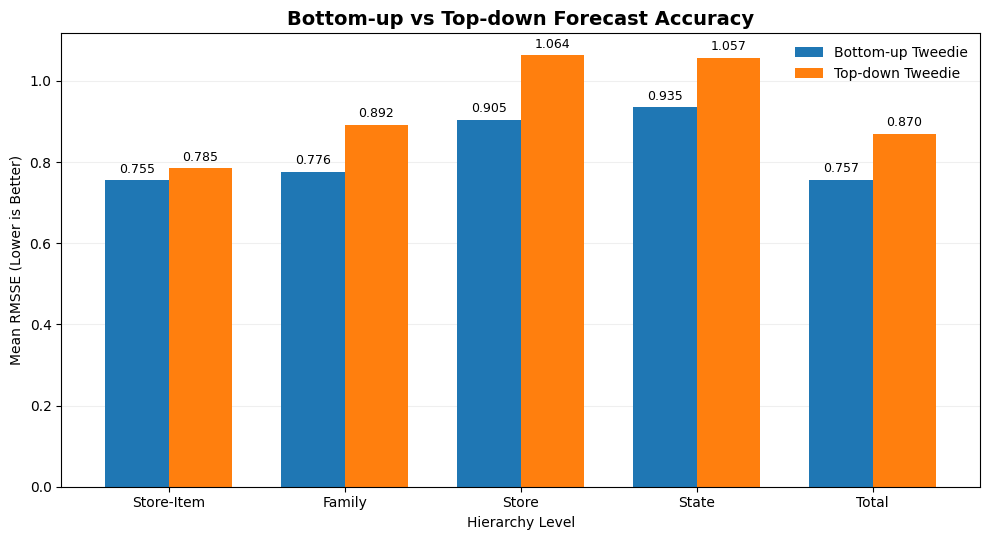

Hierarchical accuracy figure saved.


In [23]:

# 6.1 Visualise hierarchical forecasting performance

import matplotlib.pyplot as plt

levels = ["Store-Item", "Family", "Store", "State", "Total"]
models = ["Tweedie25 Bottom-up", "Tweedie Top-down"]

chart_data = hierarchy_summary.loc[
    hierarchy_summary["model"].isin(models),
    ["level", "model", "mean_rmsse"]
].copy()

chart_data = chart_data.pivot(
    index="level", columns="model", values="mean_rmsse"
).reindex(levels)

ax = chart_data[models].plot(kind="bar", figsize=(10, 5.5), width=0.72)

ax.set_title("Bottom-up vs Top-down Forecast Accuracy", fontsize=14, weight="bold")
ax.set_xlabel("Hierarchy Level")
ax.set_ylabel("Mean RMSSE (Lower is Better)")
ax.set_xticklabels(levels, rotation=0)
ax.legend(["Bottom-up Tweedie", "Top-down Tweedie"], frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3, fontsize=9)

plt.tight_layout()

FIG_DIR = BASE / "figures" / "hierarchical"
FIG_DIR.mkdir(parents=True, exist_ok=True)
plt.savefig(FIG_DIR / "bottomup_vs_topdown_rmsse.png", dpi=300, bbox_inches="tight")
plt.show()

print("Hierarchical accuracy figure saved.")



### 6.2. Allocation Window Sensitivity

**Purpose.** Visualise how historical allocation windows influence Top-down forecast accuracy across hierarchy levels.

**Method.** Compare mean RMSSE for 30-, 90-, 180- and 365-day allocation windows across eight backtesting blocks.

**Output.** A line chart illustrating the relationship between allocation window length and hierarchical forecasting accuracy.

**Limitation.** Results reflect exploratory sensitivity analysis using the same retrospective backtesting periods. Total level is excluded because all allocation windows produce identical Total forecasts.


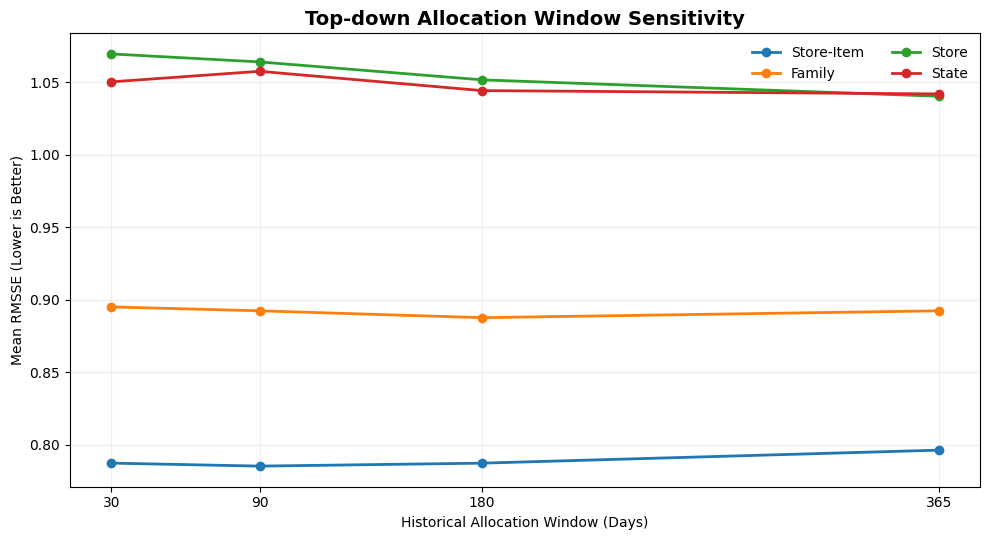

Allocation window sensitivity figure saved.


In [24]:

# 6.2 Visualise allocation window sensitivity

import matplotlib.pyplot as plt

levels = ["Store-Item", "Family", "Store", "State"]

plot_data = sensitivity_summary.pivot(
    index="window_days", columns="level", values="mean_rmsse"
).reindex(index=[30, 90, 180, 365], columns=levels)

fig, ax = plt.subplots(figsize=(10, 5.5))

for level in levels:
    ax.plot(plot_data.index, plot_data[level], marker="o",
            linewidth=2, markersize=6, label=level)

ax.set_title("Top-down Allocation Window Sensitivity", fontsize=14, weight="bold")
ax.set_xlabel("Historical Allocation Window (Days)")
ax.set_ylabel("Mean RMSSE (Lower is Better)")
ax.set_xticks([30, 90, 180, 365])
ax.legend(frameon=False, ncol=2)
ax.grid(alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIG_DIR / "allocation_window_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()

print("Allocation window sensitivity figure saved.")



### 6.3. Training Window Sensitivity

**Purpose.** Visualise the effect of historical training window length on independent Total-level forecasting accuracy.

**Method.** Compare mean RMSSE across eight backtesting blocks for 90-, 180- and 365-day training windows. Include Tweedie Bottom-up as a reference benchmark.

**Output.** A publication-ready chart illustrating the impact of training history on aggregate forecasting performance.

**Limitation.** The comparison is exploratory and uses the same retrospective backtesting periods. The selected training window is not independently validated on an unseen period.



### 6.3. Training Window Sensitivity

**Purpose.** Visualise the effect of historical training window length on independent Total-level forecasting accuracy.

**Method.** Compare mean RMSSE across eight backtesting blocks for 90-, 180- and 365-day training windows. Include Tweedie Bottom-up as a reference benchmark.

**Output.** A publication-ready chart illustrating the impact of training history on aggregate forecasting performance.

**Limitation.** The comparison is exploratory and uses the same retrospective backtesting periods. The selected training window is not independently validated on an unseen period.


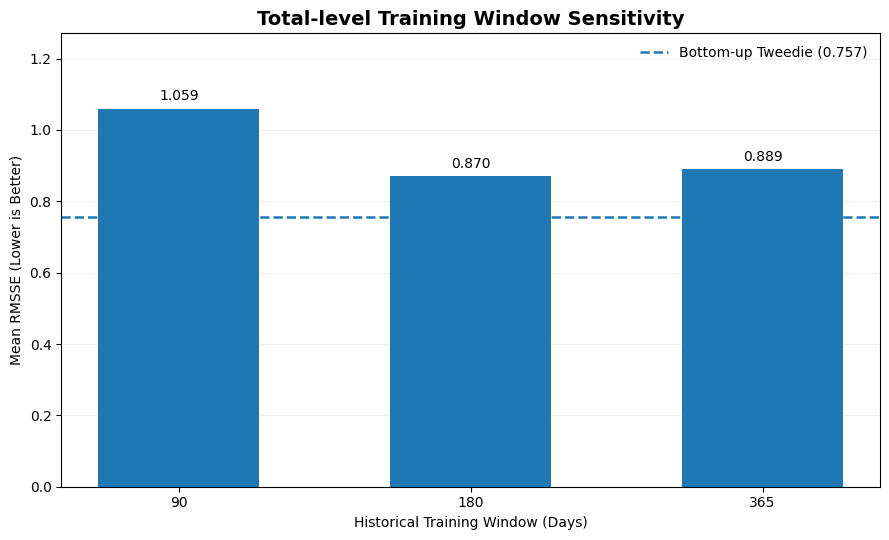

Training window sensitivity figure saved.


In [25]:

# 6.3 Visualise Total-level training window sensitivity

import matplotlib.pyplot as plt

plot_data = training_window_summary.loc[[90, 180, 365], "mean_rmsse"]
bu_reference = hierarchy_summary.loc[
    (hierarchy_summary["level"] == "Total") &
    (hierarchy_summary["model"] == "Tweedie25 Bottom-up"),
    "mean_rmsse"
].iloc[0]

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(plot_data.index.astype(str), plot_data.values, width=0.55)

ax.axhline(bu_reference, linestyle="--", linewidth=1.8,
           label=f"Bottom-up Tweedie ({bu_reference:.3f})")

ax.set_title("Total-level Training Window Sensitivity", fontsize=14, weight="bold")
ax.set_xlabel("Historical Training Window (Days)")
ax.set_ylabel("Mean RMSSE (Lower is Better)")
ax.set_ylim(0, plot_data.max() * 1.2)
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=10)

plt.tight_layout()
plt.savefig(FIG_DIR / "training_window_sensitivity.png", dpi=300, bbox_inches="tight")
plt.show()

print("Training window sensitivity figure saved.")



## 7. Final Findings, Limitations and Reproducibility

### 7.1. Final Findings and Discussion

**Finding 1 — Bottom-up achieved stronger overall accuracy.**

Across eight backtesting blocks, Tweedie Bottom-up achieved lower mean RMSSE than proportional Top-down at all five hierarchy levels:

| Level | Bottom-up RMSSE | Top-down RMSSE |
|---|---:|---:|
| Store–Item | 0.7550 | 0.7851 |
| Family | 0.7765 | 0.8923 |
| Store | 0.9047 | 1.0640 |
| State | 0.9353 | 1.0575 |
| Total | 0.7569 | 0.8702 |

Bottom-up outperformed Top-down in all eight blocks at Store–Item, Family and Store levels. However, Top-down performed better in two blocks at State level and three blocks at Total level.

**Finding 2 — Historical allocation proportions affect lower-level accuracy.**

The best allocation window varied by hierarchy level. The 90-day window achieved the lowest Store–Item RMSSE, while 180 days performed best at Family level and 365 days at Store and State levels.

Short allocation windows also introduced zero-weight risks. The 30-day specification assigned zero forecasts to approximately 168 series per block, of which around 49 subsequently recorded positive demand.

**Finding 3 — Longer training histories do not guarantee better forecasts.**

The 180-day aggregate training window achieved the lowest mean Total-level RMSSE (0.8702), compared with 1.0591 for 90 days and 0.8893 for 365 days.

Although 365 days performed best in individual periods, the 180-day specification achieved stronger average performance across the eight blocks.

**Finding 4 — Forecast coherence does not guarantee accuracy.**

All Top-down allocations reconciled with their original Total forecasts. Nevertheless, coherent predictions could still produce substantial errors at Store–Item, Family and Store levels.

**Business Implications.**

For the evaluated retail subset, Bottom-up Tweedie is the strongest candidate for operational demand planning because it combines relatively strong Store–Item accuracy with better aggregate forecasting performance.

Independent Total-level forecasts may still provide useful supplementary information for aggregate planning and forecast monitoring.

**Limitations.**

- The experiments cover a 10-store development subset rather than the complete Favorita store network.
- Evaluation cohorts were selected retrospectively, potentially introducing selection bias.
- The forecasting setup uses a rolling 16-day-ahead horizon rather than a single fixed-origin 16-day forecast.
- Top-down allocation assumes historical demand proportions remain sufficiently stable.
- Model and allocation specifications were compared on the same eight backtesting blocks; their selection is exploratory rather than independently validated.
- Historical observation coverage changes over time, partly affecting aggregate demand comparability.
- Forecasting accuracy does not directly demonstrate reduced stockouts, inventory costs or improved replenishment outcomes.

**Conclusion.**

The experiments demonstrate that hierarchical forecasting performance depends on the level of aggregation, forecast bias, training history and allocation strategy. Bottom-up Tweedie provided the most consistent overall accuracy, while proportional Top-down remained competitive in selected aggregate-level periods.



### 7.2. Output and Reproducibility Validation

**Purpose.** Verify that the forecasting experiments have produced all required result files and figures.

**Method.** Check the existence and structure of evaluation outputs, sensitivity analysis results and final visualisations.

**Output.** A reproducibility checklist identifying available and missing project artifacts.

**Limitation.** File validation confirms that outputs exist but does not replace a full Restart & Run All test.


In [26]:

# 7.2 Validate final Notebook 07 outputs

required_outputs = {
    "Total-level metrics": RES / "total_8block_metrics.csv",
    "Hierarchical metrics": RES / "hierarchy_8block_metrics.csv",
    "Hierarchical summary": RES / "hierarchy_8block_summary.csv",
    "Allocation sensitivity": RES / "allocation_sensitivity_summary.csv",
    "Training sensitivity": RES / "training_window_summary.csv",
    "Top-down predictions": RES / "topdown_total_8blocks.csv",
    "Hierarchy comparison figure": FIG_DIR / "bottomup_vs_topdown_rmsse.png",
    "Allocation sensitivity figure": FIG_DIR / "allocation_window_sensitivity.png",
    "Training sensitivity figure": FIG_DIR / "training_window_sensitivity.png"
}

checks = pd.DataFrame([
    {"artifact": name, "exists": path.exists(),
     "size_kb": round(path.stat().st_size / 1024, 1) if path.exists() else 0}
    for name, path in required_outputs.items()
])

print("Notebook 07 output validation:")
print(checks.to_string(index=False))

assert checks["exists"].all(), "Missing required output files"
assert (checks["size_kb"] > 0).all(), "Empty output files"

assert len(hierarchy_metrics) == 8 * 5 * 4
assert len(sensitivity_metrics) == 8 * 5 * 4
assert len(training_window_metrics) == 8 * 3

print("\nAll required outputs validated.")
print(f"Hierarchical comparisons: {len(hierarchy_metrics)}")
print(f"Allocation sensitivity comparisons: {len(sensitivity_metrics)}")
print(f"Training sensitivity comparisons: {len(training_window_metrics)}")


Notebook 07 output validation:
                     artifact  exists  size_kb
          Total-level metrics    True      3.1
         Hierarchical metrics    True     13.4
         Hierarchical summary    True      1.7
       Allocation sensitivity    True      1.4
         Training sensitivity    True      0.2
         Top-down predictions    True      4.0
  Hierarchy comparison figure    True    122.0
Allocation sensitivity figure    True    134.8
  Training sensitivity figure    True    104.2

All required outputs validated.
Hierarchical comparisons: 160
Allocation sensitivity comparisons: 160
Training sensitivity comparisons: 24



## 8. Independent Final Holdout Evaluation

### 8.1. Final Test Input Validation

**Purpose.** Prepare the independent final holdout evaluation for Bottom-up and Top-down forecasting.

**Method.** Inspect saved final-test predictions from Notebook 06 and verify their dates, columns and evaluation coverage.

**Output.** Validated inputs for the final comparison on 31 July–15 August 2017.

**Limitation.** Model specifications have already been selected through exploratory backtesting. No further hyperparameter or allocation-window tuning will be performed using the final test.


In [27]:

# 8.1 Inspect final test predictions from Notebook 06

final_path = BASE / "results" / "global_lgbm_25_predictions.parquet"
assert final_path.exists(), f"Missing file: {final_path}"

final_pred = pd.read_parquet(final_path)

print("Final test prediction file loaded.")
print(f"Rows: {len(final_pred):,}")
print(f"Columns: {len(final_pred.columns)}")

print("\nAvailable columns:")
print(final_pred.columns.tolist())

if "date" in final_pred.columns:
    final_pred["date"] = pd.to_datetime(final_pred["date"])
    print(f"\nDate range: {final_pred['date'].min().date()} to {final_pred['date'].max().date()}")

print("\nFirst 5 rows:")
print(final_pred.head().to_string(index=False))


Final test prediction file loaded.
Rows: 77,815
Columns: 7

Available columns:
['date', 'store_nbr', 'item_nbr', 'unit_sales', 'moving_avg_28', 'log_25', 'tweedie_25']

Date range: 2017-07-31 to 2017-08-15

First 5 rows:
      date  store_nbr  item_nbr  unit_sales  moving_avg_28   log_25  tweedie_25
2017-07-31         10    105576        13.0       8.571428 8.164884    9.509945
2017-08-01         10    105576         3.0       8.571428 7.810699    8.747580
2017-08-02         10    105576        22.0       8.750000 6.699502    7.853485
2017-08-03         10    105576        22.0       8.571428 7.035896    7.879546
2017-08-04         10    105576        17.0       8.535714 6.058285    7.061127



### 8.2. Final Test Evaluation Cohort

**Purpose.** Reproduce the final evaluation cohort used in Notebook 06.

**Method.** Select Store–Item series with positive demand during the 90 days preceding the training cutoff (14 July 2017). Retain only series with complete actual observations and model predictions across the 16-day test period.

**Output.** A consistent final-test cohort for Bottom-up and Top-down forecasting comparisons.

**Limitation.** Requiring complete observations across the test period introduces retrospective eligibility selection. Activity classification itself uses only pre-cutoff historical information.


In [29]:

# 8.2 Reproduce the audited final-test evaluation cohort

FINAL_START = pd.Timestamp("2017-07-31")
FINAL_END = pd.Timestamp("2017-08-15")
FINAL_CUTOFF = FINAL_START - pd.Timedelta(days=H + 1)
ACTIVE_START = FINAL_CUTOFF - pd.Timedelta(days=89)

assert final_pred["date"].nunique() == 16
assert final_pred["date"].min() == FINAL_START
assert final_pred["date"].max() == FINAL_END
assert not final_pred.duplicated(KEYS).any()

# Identify active series using pre-cutoff history
active = hist.loc[
    hist["date"].between(ACTIVE_START, FINAL_CUTOFF) &
    hist["unit_sales"].gt(0), SERIES_KEYS
].drop_duplicates()

quality = final_pred.groupby(SERIES_KEYS).agg(
    n_days=("date", "nunique"),
    n_actual=("unit_sales", "count"),
    n_ma28=("moving_avg_28", "count"),
    n_log=("log_25", "count"),
    n_tweedie=("tweedie_25", "count")
).reset_index()

quality["active"] = pd.MultiIndex.from_frame(quality[SERIES_KEYS]).isin(
    pd.MultiIndex.from_frame(active)
)
quality["complete"] = quality[
    ["n_days", "n_actual", "n_ma28", "n_log", "n_tweedie"]
].eq(16).all(axis=1)

candidates = quality.loc[quality["active"] & quality["complete"], SERIES_KEYS].copy()

# Load the audited cohort from Notebook 05
cohort_path = BASE / "results" / "nb05_active_test_series_corrected.parquet"
assert cohort_path.exists(), f"Missing audited cohort: {cohort_path}"

final_cohort = pd.read_parquet(cohort_path, columns=SERIES_KEYS).drop_duplicates()
assert len(final_cohort) == 4378

# Compare the two cohort definitions
extra = candidates.merge(final_cohort, on=SERIES_KEYS, how="left", indicator=True)
extra = extra.loc[extra["_merge"] == "left_only", SERIES_KEYS]

missing = final_cohort.merge(candidates, on=SERIES_KEYS, how="left", indicator=True)
missing = missing.loc[missing["_merge"] == "left_only", SERIES_KEYS]

print("Final cohort reconciliation:")
print(f"Active and complete candidates: {len(candidates):,}")
print(f"Notebook 05 audited cohort: {len(final_cohort):,}")
print(f"Extra candidates: {len(extra):,}")
print(f"Audited series missing from candidates: {len(missing):,}")

# Diagnose exclusions using the earlier Notebook 05 audit
audit_path = BASE / "results" / "nb05_eligibility_audit.parquet"
if audit_path.exists():
    audit = pd.read_parquet(audit_path)
    diagnostics = extra.merge(
        audit[SERIES_KEYS + ["covered", "scale_ok"]],
        on=SERIES_KEYS, how="left", validate="one_to_one"
    )
    print("\nExtra-series eligibility diagnostics:")
    print(f"Not covered in Notebook 05: {(diagnostics['covered'] == False).sum()}")
    print(f"Invalid RMSSE scale: {(diagnostics['scale_ok'] == False).sum()}")

assert missing.empty, "Some audited series are missing from final-test candidates"

# Use the previously audited evaluation cohort
final_eval = final_pred.merge(final_cohort, on=SERIES_KEYS,
                              how="inner", validate="many_to_one")

assert len(final_eval) == 70_048
assert not final_eval.duplicated(KEYS).any()
assert np.isfinite(final_eval[["unit_sales"] + PRED_COLS].to_numpy()).all()

print("\nFinal test cohort validated.")
print(f"Training cutoff: {FINAL_CUTOFF.date()}")
print(f"Evaluation series: {len(final_cohort):,}")
print(f"Evaluation rows: {len(final_eval):,}")
print(f"Evaluation dates: {final_eval['date'].nunique()}")


Final cohort reconciliation:
Active and complete candidates: 4,389
Notebook 05 audited cohort: 4,378
Extra candidates: 11
Audited series missing from candidates: 0

Extra-series eligibility diagnostics:
Not covered in Notebook 05: 10
Invalid RMSSE scale: 11

Final test cohort validated.
Training cutoff: 2017-07-14
Evaluation series: 4,378
Evaluation rows: 70,048
Evaluation dates: 16



### 8.3. Final Holdout Feature Preparation

**Purpose.** Prepare the independent Total-level forecasting dataset for the final holdout period.

**Method.** Aggregate historical demand from the audited 4,378 Store–Item series. Generate the same ten leakage-safe features used in the eight-block experiments, excluding closed-store observations.

**Output.** A 180-day training dataset and 16 daily forecast feature vectors for 31 July–15 August 2017.

**Limitation.** The evaluation cohort is retrospectively selected based on complete test coverage. The model uses a fixed training cutoff, while demand features are updated using observations available at least 16 days before each target date.


In [30]:

# 8.3 Prepare final holdout Total-level features

FINAL_FEATURE_CUTOFF = FINAL_END - pd.Timedelta(days=H)

# Historical data for the audited final-test cohort
h = hist.loc[hist["date"] <= FINAL_FEATURE_CUTOFF].merge(
    final_cohort, on=SERIES_KEYS, how="inner", validate="many_to_one"
)
sales = h.groupby("date")["unit_sales"].sum(min_count=1)
dates = pd.date_range(sales.index.min(), FINAL_END, freq="D")

final_daily = pd.DataFrame(index=dates)
final_daily.index.name = "date"
final_daily["total_sales"] = sales.reindex(dates)

# Calendar features
final_daily["dow"] = final_daily.index.dayofweek
final_daily["month"] = final_daily.index.month
final_daily["is_weekend"] = (final_daily["dow"] >= 5).astype("int8")
final_daily["is_payday"] = ((final_daily.index.day == 15) |
                            final_daily.index.is_month_end).astype("int8")

# Historical demand features with the same fallback as Cell 3.5
s = final_daily["total_sales"]
for lag in [16, 21, 28]:
    final_daily[f"lag_{lag}"] = s.shift(lag).fillna(s.shift(lag + 7)).fillna(s.shift(lag + 14))

shifted = s.shift(H)
final_daily["roll_mean_28"] = shifted.rolling(28, min_periods=21).mean()
final_daily["roll_std_28"] = shifted.rolling(28, min_periods=21).std()
final_daily["same_weekday_mean_4"] = pd.concat(
    [s.shift(k) for k in [21, 28, 35, 42]], axis=1
).mean(axis=1)

# Training and final forecast features
train_start = FINAL_CUTOFF - pd.Timedelta(days=179)
final_train = final_daily.loc[train_start:FINAL_CUTOFF].dropna(
    subset=["total_sales"] + TOTAL_FEATURES
)
final_forecast = final_daily.loc[FINAL_START:FINAL_END].copy()

assert len(final_cohort) == 4378
assert len(final_forecast) == 16
assert final_forecast[TOTAL_FEATURES].notna().all().all()
assert final_forecast["total_sales"].isna().all()
assert final_train.index.max() <= FINAL_CUTOFF

# Total-level historical RMSSE denominator
final_history = final_daily.loc[:FINAL_CUTOFF, "total_sales"].astype("float64")
final_scale = final_history.diff().pow(2).mean()
assert np.isfinite(final_scale) and final_scale > 0

print("Final holdout feature preparation completed.")
print(f"Evaluation series: {len(final_cohort):,}")
print(f"Training period: {train_start.date()} to {FINAL_CUTOFF.date()}")
print(f"Training observations: {len(final_train):,}")
print(f"Latest available feature date: {FINAL_FEATURE_CUTOFF.date()}")
print(f"Forecast period: {FINAL_START.date()} to {FINAL_END.date()}")
print(f"Forecast observations: {len(final_forecast)}")
print(f"Features: {len(TOTAL_FEATURES)}")
print(f"Historical Total RMSSE scale: {final_scale:,.2f}")

print("\nFirst 5 forecast features:")
print(final_forecast[TOTAL_FEATURES].head().round(2).to_string())


Final holdout feature preparation completed.
Evaluation series: 4,378
Training period: 2017-01-16 to 2017-07-14
Training observations: 180
Latest available feature date: 2017-07-30
Forecast period: 2017-07-31 to 2017-08-15
Forecast observations: 16
Features: 10
Historical Total RMSSE scale: 19,945,974.40

First 5 forecast features:
            dow  month  is_weekend  is_payday        lag_16        lag_21        lag_28  roll_mean_28  roll_std_28  same_weekday_mean_4
date                                                                                                                                   
2017-07-31    0      7           0          1  29487.919922  28531.490234  29891.779297      26845.04      4843.92         26547.199219
2017-08-01    1      8           0          0  33366.199219  22370.119141  26738.310547      27054.38      4997.70         24777.029297
2017-08-02    2      8           0          0  26737.179688  23554.179688  27706.490234      27117.15      4981.69        


### 8.4. Final Holdout Model Training

**Purpose.** Train the selected independent Total-level forecasting model for the final holdout period.

**Method.** Fit Tweedie LightGBM using the preceding 180 calendar days. Select boosting iterations through chronological validation and refit on all available training observations. Apply the same features and hyperparameters used during backtesting.

**Output.** Sixteen independent Total-level demand forecasts for 31 July–15 August 2017.

**Limitation.** The training specification was selected through earlier backtesting experiments. Final holdout outcomes will be used for evaluation only, without additional model tuning.


In [31]:

# 8.4 Train the selected Top-down model on the final holdout

tr, va = final_train.iloc[:-28], final_train.iloc[-28:]
assert len(tr) == 152 and len(va) == 28
assert final_train.index.max() == FINAL_CUTOFF

# Chronological validation for boosting iterations
pilot = LGBMRegressor(**TOPDOWN_PARAMS)
pilot.fit(tr[TOTAL_FEATURES], tr["total_sales"],
          eval_set=[(va[TOTAL_FEATURES], va["total_sales"])],
          callbacks=[early_stopping(40, verbose=False)])

final_best_iter = int(pilot.best_iteration_)
assert final_best_iter > 0

# Refit on all 180 training observations
final_model = LGBMRegressor(**{**TOPDOWN_PARAMS, "n_estimators": final_best_iter})
final_model.fit(final_train[TOTAL_FEATURES], final_train["total_sales"])

# Independent Total forecasts
final_yhat = np.maximum(final_model.predict(final_forecast[TOTAL_FEATURES]), 0)
final_total_forecast = pd.DataFrame({
    "date": final_forecast.index, "top_down_total": final_yhat
})

assert len(final_total_forecast) == 16
assert np.isfinite(final_yhat).all()
assert (final_yhat >= 0).all()

final_total_forecast.to_csv(RES / "final_holdout_total_forecasts.csv", index=False)

print("Final holdout Total-level model trained.")
print(f"Training observations: {len(final_train)}")
print(f"Validation observations: {len(va)}")
print(f"Selected iterations: {final_best_iter}")
print(f"Forecast observations: {len(final_total_forecast)}")
print(f"Mean forecast demand: {final_yhat.mean():,.2f}")

print("\nFirst 5 Total-level forecasts:")
print(final_total_forecast.head().round(2).to_string(index=False))
print("\nFinal holdout forecasts saved.")


Final holdout Total-level model trained.
Training observations: 180
Validation observations: 28
Selected iterations: 62
Forecast observations: 16
Mean forecast demand: 28,142.37

First 5 Total-level forecasts:
      date  top_down_total
2017-07-31        27081.59
2017-08-01        26632.50
2017-08-02        26887.23
2017-08-03        23903.40
2017-08-04        26887.23

Final holdout forecasts saved.



### 8.5. Final Holdout Top-down Disaggregation

**Purpose.** Disaggregate independent Total-level forecasts into Store–Item predictions for the final holdout period.

**Method.** Calculate fixed Store–Item sales proportions using the 90 calendar days preceding the training cutoff. Apply these weights to the 16 daily Total forecasts and verify reconciliation.

**Output.** Top-down Store–Item forecasts for 4,378 evaluation series across 16 days.

**Limitation.** Fixed historical weights may not capture changing product demand. The evaluation cohort was selected retrospectively using complete test-period coverage.


In [32]:

# 8.5 Disaggregate final holdout Total forecasts to Store-Item

share_start = FINAL_CUTOFF - pd.Timedelta(days=89)

# Historical sales proportions using only pre-cutoff data
recent = hist.loc[hist["date"].between(share_start, FINAL_CUTOFF)].merge(
    final_cohort, on=SERIES_KEYS, how="inner", validate="many_to_one"
).copy()
recent["positive_sales"] = recent["unit_sales"].clip(lower=0).astype("float64")

sales = recent.groupby(SERIES_KEYS, as_index=False)["positive_sales"].sum()
final_shares = final_cohort.merge(sales, on=SERIES_KEYS, how="left", validate="one_to_one")
final_shares["positive_sales"] = final_shares["positive_sales"].fillna(0)

total_sales = final_shares["positive_sales"].sum()
assert total_sales > 0
final_shares["share"] = final_shares["positive_sales"] / total_sales

assert len(final_shares) == 4378
assert final_shares["share"].ge(0).all()
assert np.isclose(final_shares["share"].sum(), 1, rtol=0, atol=1e-12)

# Apply the same weights to all 16 Total forecasts
final_alloc = final_eval.merge(
    final_shares[SERIES_KEYS + ["share"]], on=SERIES_KEYS,
    how="left", validate="many_to_one"
)
final_alloc = final_alloc.merge(
    final_total_forecast, on="date", how="left", validate="many_to_one"
)
final_alloc["top_down_si"] = final_alloc["top_down_total"].astype("float64") * final_alloc["share"]

assert len(final_alloc) == 70_048
assert not final_alloc.duplicated(KEYS).any()
assert final_alloc[["share", "top_down_total", "top_down_si"]].notna().all().all()
assert final_alloc["top_down_si"].ge(0).all()

# Reconciliation: allocated forecasts must equal independent Total forecasts
reconciliation = final_alloc.groupby("date", as_index=False).agg(
    original_total=("top_down_total", "first"),
    allocated_total=("top_down_si", "sum"),
    n_series=("item_nbr", "count")
)
reconciliation["difference"] = reconciliation["allocated_total"] - reconciliation["original_total"]

max_error = reconciliation["difference"].abs().max()
assert reconciliation["n_series"].eq(4378).all()
assert max_error < 1e-6

# Save final holdout outputs
final_shares.to_parquet(RES / "final_holdout_historical_shares.parquet", index=False)
final_alloc.to_parquet(RES / "final_holdout_store_item_predictions.parquet", index=False)

print("Final holdout Top-down disaggregation completed.")
print(f"Allocation period: {share_start.date()} to {FINAL_CUTOFF.date()}")
print(f"Store-Item series: {len(final_shares):,}")
print(f"Forecast rows: {len(final_alloc):,}")
print(f"Forecast dates: {final_alloc['date'].nunique()}")
print(f"Historical weight sum: {final_shares['share'].sum():.12f}")
print(f"Zero-weight series: {(final_shares['share'] == 0).sum():,}")
print(f"Maximum reconciliation error: {max_error:.12f}")

print("\nFirst 5 Store-Item forecasts:")
print(final_alloc[KEYS + ["share", "top_down_si"]].head().round(6).to_string(index=False))

print("\nFinal holdout predictions saved.")


Final holdout Top-down disaggregation completed.
Allocation period: 2017-04-16 to 2017-07-14
Store-Item series: 4,378
Forecast rows: 70,048
Forecast dates: 16
Historical weight sum: 1.000000000000
Zero-weight series: 0
Maximum reconciliation error: 0.000000000000

First 5 Store-Item forecasts:
      date  store_nbr  item_nbr    share  top_down_si
2017-07-31         10    105576 0.000428    11.590712
2017-08-01         10    105576 0.000428    11.398507
2017-08-02         10    105576 0.000428    11.507528
2017-08-03         10    105576 0.000428    10.230473
2017-08-04         10    105576 0.000428    11.507528

Final holdout predictions saved.



### 8.6. Final Holdout Hierarchical Evaluation

**Purpose.** Evaluate Bottom-up and Top-down forecasting strategies on the final holdout period across five hierarchy levels.

**Method.** Aggregate Store–Item forecasts into Family, Store, State and Total levels. Calculate historical RMSSE scales using consecutive observed days before the training cutoff. Compare MA28 Bottom-up, Log25 Bottom-up, Tweedie25 Bottom-up and Tweedie Top-down using identical evaluation cohorts.

**Output.** Final holdout RMSSE, WAPE and signed bias for all five hierarchy levels, with consistency checks against Notebook 06.

**Limitation.** Results cover one 16-day holdout period. The evaluation cohort was retrospectively selected, and Bottom-up models have different training structures from the independent Total-level model. Final-test results will not be used for further tuning.


In [35]:

# 8.6 Final holdout evaluation across five hierarchy levels

# Load dimension tables
dim_candidates = [p.parent for p in BASE.rglob("stores.parquet")
                  if (p.parent / "items.parquet").exists()]
assert dim_candidates, "Cannot find dimension tables"
DIM = dim_candidates[0]

stores = pd.read_parquet(DIM / "stores.parquet", columns=["store_nbr", "state"])
items = pd.read_parquet(DIM / "items.parquet", columns=["item_nbr", "family"])
assert stores["store_nbr"].is_unique and items["item_nbr"].is_unique

# Attach hierarchy information
final_data = final_alloc.merge(stores, on="store_nbr", validate="many_to_one")
final_data = final_data.merge(items, on="item_nbr", validate="many_to_one")
final_data["total_key"] = "all"

history_final = hist.loc[hist["date"] <= FINAL_CUTOFF].merge(
    final_cohort, on=SERIES_KEYS, validate="many_to_one"
)
history_final = history_final.merge(stores, on="store_nbr", validate="many_to_one")
history_final = history_final.merge(items, on="item_nbr", validate="many_to_one")
history_final["total_key"] = "all"

FINAL_LEVELS = {
    "Store-Item": ["store_nbr", "item_nbr"],
    "Family": ["family"],
    "Store": ["store_nbr"],
    "State": ["state"],
    "Total": ["total_key"]
}

FINAL_MODELS = {
    "MA28 Bottom-up": "moving_avg_28",
    "Log25 Bottom-up": "log_25",
    "Tweedie25 Bottom-up": "tweedie_25",
    "Tweedie Top-down": "top_down_si"
}

final_rows, final_level_parts = [], []

for level, keys in FINAL_LEVELS.items():
    # Historical RMSSE scales using consecutive observed days
    past = history_final.groupby(keys + ["date"], observed=True)["unit_sales"].sum().reset_index()
    past = past.sort_values(keys + ["date"])

    g = past.groupby(keys, observed=True)
    prev = g["unit_sales"].shift(1)
    prev_date = g["date"].shift(1)
    consecutive = (past["date"] - prev_date).eq(pd.Timedelta(days=1))

    past["sq_diff"] = (past["unit_sales"] - prev).pow(2).where(consecutive)
    scales = past.groupby(keys, observed=True)["sq_diff"].mean().rename("scale").reset_index()

    # Aggregate actual demand and forecasts
    agg = final_data.groupby(keys + ["date"], observed=True).agg(
        actual=("unit_sales", "sum"),
        moving_avg_28=("moving_avg_28", "sum"),
        log_25=("log_25", "sum"),
        tweedie_25=("tweedie_25", "sum"),
        top_down_si=("top_down_si", "sum")
    ).reset_index()

    data = agg.merge(scales, on=keys, validate="many_to_one")
    data = data.loc[np.isfinite(data["scale"]) & data["scale"].gt(0)].copy()

    assert not data.empty
    assert not data.duplicated(keys + ["date"]).any()
    assert data[["actual"] + list(FINAL_MODELS.values())].notna().all().all()

    for model, col in FINAL_MODELS.items():
        error = data[col] - data["actual"]
        detail = data[keys + ["scale"]].copy()
        detail["sq_error"] = error.pow(2)

        groups = detail.groupby(keys, observed=True).agg(
            mse=("sq_error", "mean"),
            scale=("scale", "first")
        )

        final_rows.append({
            "level": level, "model": model, "groups": len(groups),
            "rmsse": np.sqrt(groups["mse"] / groups["scale"]).mean(),
            "wape_pct": error.abs().sum() / data["actual"].sum() * 100,
            "bias_pct": error.sum() / data["actual"].sum() * 100
        })

    data["level"] = level
    final_level_parts.append(data)
    print(f"{level}: {data[keys].drop_duplicates().shape[0]:,} groups evaluated")

final_holdout_metrics = pd.DataFrame(final_rows)
final_holdout_levels = pd.concat(final_level_parts, ignore_index=True)

# Verify Top-down reconciliation
total_check = final_data.groupby("date")["top_down_si"].sum().sort_index()
total_ref = final_total_forecast.set_index("date")["top_down_total"].sort_index()
assert np.allclose(total_check, total_ref, rtol=0, atol=1e-6)

print("\nFinal holdout hierarchical comparison:")
print(final_holdout_metrics.round(4).to_string(index=False))

# Verify Store-Item consistency with Notebook 06
reference = {
    "MA28 Bottom-up": 0.72735,
    "Log25 Bottom-up": 0.6973,
    "Tweedie25 Bottom-up": 0.7081
}

print("\nNotebook 06 Store-Item RMSSE consistency:")
for model, expected in reference.items():
    observed = final_holdout_metrics.loc[
        (final_holdout_metrics["level"] == "Store-Item") &
        (final_holdout_metrics["model"] == model), "rmsse"
    ].iloc[0]
    diff = abs(observed - expected)
    print(f"{model}: NB07={observed:.5f} | NB06~{expected:.5f} | Difference={diff:.6f}")
    assert diff < 0.001, f"{model}: RMSSE mismatch"

final_holdout_metrics.to_csv(RES / "final_holdout_hierarchy_metrics.csv", index=False)
final_holdout_levels.to_parquet(RES / "final_holdout_hierarchy_predictions.parquet", index=False)

print("\nFinal holdout hierarchical evaluation saved.")


Store-Item: 4,378 groups evaluated
Family: 30 groups evaluated
Store: 10 groups evaluated
State: 3 groups evaluated
Total: 1 groups evaluated

Final holdout hierarchical comparison:
     level               model  groups  rmsse  wape_pct  bias_pct
Store-Item      MA28 Bottom-up    4378 0.7273   58.7706    6.8974
Store-Item     Log25 Bottom-up    4378 0.6973   50.8183  -21.2086
Store-Item Tweedie25 Bottom-up    4378 0.7081   52.5117    0.1939
Store-Item    Tweedie Top-down    4378 0.7484   63.4701   11.0887
    Family      MA28 Bottom-up      30 0.9887   16.0717    6.8974
    Family     Log25 Bottom-up      30 1.1339   22.3569  -21.2086
    Family Tweedie25 Bottom-up      30 0.8900   11.8763    0.1939
    Family    Tweedie Top-down      30 0.9634   17.9130   11.0887
     Store      MA28 Bottom-up      10 0.8573   17.4703    6.8974
     Store     Log25 Bottom-up      10 1.0161   21.7860  -21.2086
     Store Tweedie25 Bottom-up      10 0.6353   12.4746    0.1939
     Store    Tweedie Top-


### 8.7. Final Holdout Findings and Conclusion

**Purpose.** Summarise the final holdout results and assess whether the earlier hierarchical forecasting findings remain consistent on a later evaluation period.

**Method.** Compare Bottom-up and proportional Top-down forecasts across five hierarchy levels using the same 4,378 Store–Item series and the fixed modelling specifications.

**Output.** Final conclusions on forecast accuracy, bias, hierarchical performance and generalisation limitations.

#### Finding 1 — Bottom-up Retained Stronger Hierarchical Accuracy

During the final holdout period (31 July–15 August 2017), Tweedie Bottom-up achieved lower RMSSE than proportional Top-down at all five hierarchy levels.

| Level | Tweedie Bottom-up | Tweedie Top-down |
|---|---:|---:|
| Store–Item | 0.7081 | 0.7484 |
| Family | 0.8900 | 0.9634 |
| Store | 0.6353 | 0.9502 |
| State | 0.7646 | 1.1585 |
| Total | 0.7362 | 1.0315 |

At Total level, Bottom-up reduced RMSSE by approximately 28.6% relative to proportional Top-down.

These results are consistent with the earlier eight-block backtesting findings, where Bottom-up also achieved lower mean RMSSE across all five hierarchy levels.

#### Finding 2 — Forecast Bias Remains Important

Tweedie Bottom-up achieved a Total-level signed bias of +0.19%, compared with +11.09% for Top-down.

Although the independent Total model produced coherent forecasts after disaggregation, its overforecasting reduced accuracy during the holdout period.

This demonstrates that forecast coherence alone does not guarantee reliable aggregate demand estimates.

#### Finding 3 — Model Selection Depends on the Decision Level

Log LightGBM achieved the lowest Store–Item RMSSE (0.6973), compared with 0.7081 for Tweedie LightGBM.

However, Log LightGBM substantially underforecast aggregate demand, with signed bias of -21.21%.

Tweedie Bottom-up therefore offered a more balanced result when both aggregate accuracy and forecast bias were considered.

#### Final Modelling Decision

Tweedie Bottom-up is selected as the preferred forecasting strategy for the evaluated retail subset because it demonstrated stronger aggregate accuracy and relatively low forecast bias across the backtesting and final holdout evaluations.

Log LightGBM remains a competitive alternative when Store–Item RMSSE is the primary objective.

#### Limitations

- The evaluation covers only the 10-store development subset.
- Store–Item eligibility was retrospectively restricted to series with complete evaluation coverage and valid RMSSE scales.
- The evaluated Top-down approach uses independent Total-level forecasting followed by fixed 90-day historical proportions; other reconciliation approaches were not tested.
- The forecasting framework uses rolling 16-day-ahead predictions, not a single fixed-origin multi-step forecast.
- The later holdout provides an additional check of the fixed Top-down specification, but the wider project has already examined this period during earlier model development.
- No actual inventory, replenishment lead-time or stockout outcomes were evaluated.

#### Conclusion

The experiments indicate that forecast performance depends on both the modelling strategy and the level of aggregation.

For this dataset, Bottom-up Tweedie provided the strongest overall hierarchical forecasting performance. Nevertheless, the results do not establish that Bottom-up is universally superior to all Top-down or reconciliation approaches.
